<a href="https://colab.research.google.com/github/aleeyaqis/ENGG2112-Crop-Weed-Segmentation/blob/main/ENGG2112.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Dataset


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import zipfile

zip_path = Path('/content/drive/MyDrive/ENGG2112/CKA_160523.zip')
dataset_path = Path('/content/CKA_160523')

if not zip_path.exists():
    raise FileNotFoundError(f"Cannot find: {zip_path}")

if not dataset_path.exists():
    with zipfile.ZipFile(zip_path, 'r') as zip_file:
        zip_file.extractall('/content')

print("Dataset found:", dataset_path.exists())
print("Folders:", [p.name for p in dataset_path.iterdir()])

Mounted at /content/drive
Dataset found: True
Folders: ['annotations', '.DS_Store', 'images']


# Check how many images in the files

In [ ]:
rgb_dir = dataset_path / 'images/rgb'
nir_dir = dataset_path / 'images/nir'
mask_dir = dataset_path / 'annotations/dlp/iMapCleaned'

rgb_files = {p.name for p in rgb_dir.glob('*.png')}
nir_files = {p.name for p in nir_dir.glob('*.png')}
mask_files = {p.name for p in mask_dir.glob('*.png')}

matched_files = sorted(rgb_files & nir_files & mask_files)

print("RGB images:", len(rgb_files))
print("NIR images:", len(nir_files))
print("Annotation masks:", len(mask_files))
print("Complete RGB + NIR + mask pairs:", len(matched_files))

print("\nFirst 5 matching filenames:")
for filename in matched_files[:5]:
    print(filename)

RGB images: 980
NIR images: 980
Annotation masks: 921
Complete RGB + NIR + mask pairs: 921

First 5 matching filenames:
bonirob_2016-05-23-10-37-10_0_frame100.png
bonirob_2016-05-23-10-37-10_0_frame101.png
bonirob_2016-05-23-10-37-10_0_frame102.png
bonirob_2016-05-23-10-37-10_0_frame103.png
bonirob_2016-05-23-10-37-10_0_frame104.png


#Check the segmentation labels

In [ ]:
import cv2
import numpy as np

# Choose one of our matched samples
sample_name = 'bonirob_2016-05-23-10-37-10_0_frame23.png'

# Read the annotation without changing its original values
mask = cv2.imread(
    str(mask_dir / sample_name),
    cv2.IMREAD_UNCHANGED
)

if mask is None:
    raise FileNotFoundError("Annotation not found!")

print("Mask shape:", mask.shape)
print("Mask data type:", mask.dtype)

# Find all unique label values
values, counts = np.unique(mask, return_counts=True)

print("\nOriginal label values:")
for value, count in zip(values, counts):
    print(f"Label {value}: {count} pixels")

Mask shape: (966, 1296)
Mask data type: uint16

Original label values:
Label 0: 1076502 pixels
Label 10000: 70117 pixels
Label 20000: 8524 pixels
Label 20001: 3817 pixels
Label 20002: 868 pixels
Label 20101: 92108 pixels


# Dataset Validation

In [ ]:
#create an empty set
all_labels=set()
checked = 0

generic_weed_pixels = 0

total_pixels=0

for filename in matched_files:

    mask = cv2.imread(
        str(mask_dir / filename),
        cv2.IMREAD_UNCHANGED
    )

    values = np.unique(mask)
    all_labels.update(values)

    checked += 1
    generic_weed_pixels += np.count_nonzero(mask == 2)
    total_pixels += mask.size

# calculate the percentage
percentage = (generic_weed_pixels/total_pixels)*100

print("Total pixels:", total_pixels)
print("Generic weed pixels:", generic_weed_pixels)
print("Generic weed percentage:", round(percentage,3), "%")
# Display all unique labels collected
print(sorted(all_labels))

print("Masks checked:", checked)
print("Number of unique labels:", len(all_labels))
print("All labels:", sorted(all_labels))

Total pixels: 1153033056
Generic weed pixels: 5463812
Generic weed percentage: 0.474 %
[np.uint16(0), np.uint16(1), np.uint16(2), np.uint16(10000), np.uint16(20000), np.uint16(20001), np.uint16(20002), np.uint16(20003), np.uint16(20004), np.uint16(20005), np.uint16(20006), np.uint16(20007), np.uint16(20008), np.uint16(20009), np.uint16(20100), np.uint16(20101), np.uint16(20102), np.uint16(20103), np.uint16(20104), np.uint16(20105)]
Masks checked: 921
Number of unique labels: 20
All labels: [np.uint16(0), np.uint16(1), np.uint16(2), np.uint16(10000), np.uint16(20000), np.uint16(20001), np.uint16(20002), np.uint16(20003), np.uint16(20004), np.uint16(20005), np.uint16(20006), np.uint16(20007), np.uint16(20008), np.uint16(20009), np.uint16(20100), np.uint16(20101), np.uint16(20102), np.uint16(20103), np.uint16(20104), np.uint16(20105)]


# Convert labels into four classes

In [ ]:
# Create a new mask filled with 255 (ignore)
new_mask = np.full(mask.shape, 255, dtype=np.uint8)

# Class 0: Soil
new_mask[np.isin(mask, [0, 1, 97])] = 0

# Class 1: Crop
new_mask[np.isin(mask, [10000, 10001, 10002])] = 1

# Class 2: Grass weed
new_mask[np.isin(mask, range(20100, 20106))] = 2

# Class 3: Dicot weed
new_mask[np.isin(mask, range(20000, 20012))] = 3

print("Original mask labels:", np.unique(mask))
print("Converted mask labels:", np.unique(new_mask))

Original mask labels: [    0     2 10000 20100]
Converted mask labels: [  0   1   2 255]


#TEST A MASK CONTAINING DICOT WEEDS

In [ ]:
sample_name = "bonirob_2016-05-23-10-37-10_0_frame23.png"

mask = cv2.imread(
    str(mask_dir / sample_name),
    cv2.IMREAD_UNCHANGED
)

print("Original labels:", np.unique(mask))

Original labels: [    0 10000 20000 20001 20002 20101]


#Visualise your converted mask

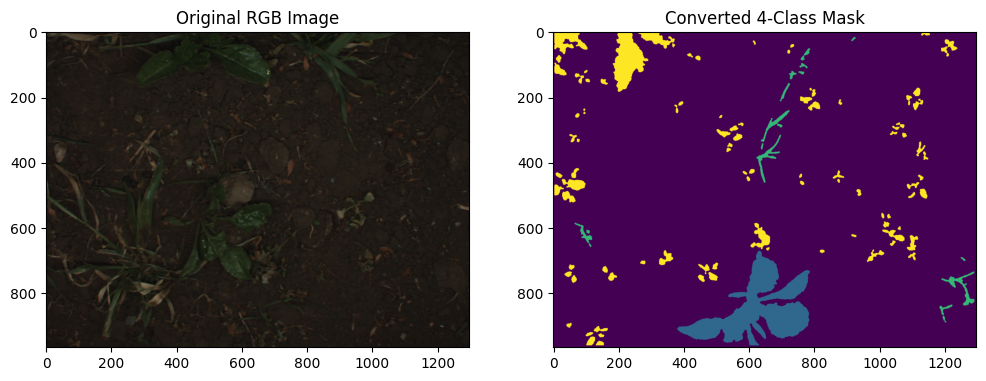

In [ ]:
import matplotlib.pyplot as plt

# Load the RGB image
rgb = cv2.imread(str(rgb_dir / sample_name))

# OpenCV uses BGR, so convert to RGB for display
rgb = cv2.cvtColor(rgb, cv2.COLOR_BGR2RGB)

# Create two plots side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Display the original photograph
axes[0].imshow(rgb)
axes[0].set_title("Original RGB Image")

# Display the converted annotation mask
axes[1].imshow(new_mask, cmap="viridis", vmin=0, vmax=3)
axes[1].set_title("Converted 4-Class Mask")

plt.show()

# Making the conversion code reusable

In [ ]:
def convert_mask(mask):
    new_mask = np.full(mask.shape, 255, dtype=np.uint8)

# Class 0: Soil
    new_mask[np.isin(mask, [0, 1, 97])] = 0

# Class 1: Crop
    new_mask[np.isin(mask, [10000, 10001, 10002])] = 1

# Class 2: Grass weed
    new_mask[np.isin(mask, range(20100, 20106))] = 2

# Class 3: Dicot weed
    new_mask[np.isin(mask, range(20000, 20012))] = 3

    return new_mask

In [ ]:
converted = convert_mask(mask)

print("Original labels:", np.unique(mask))
print("Converted labels:", np.unique(converted))

Original labels: [    0 10000 20000 20001 20002 20101]
Converted labels: [0 1 2 3]


#saving the converted masks

1. create folder for the converted masks

In [ ]:
from pathlib import Path

output_dir = Path("/content/converted_masks")
output_dir.mkdir(parents=True, exist_ok=True)

print("Output folder:", output_dir)

Output folder: /content/converted_masks


#Save converted mask

In [ ]:
output_path = output_dir / sample_name

cv2.imwrite(str(output_path), converted)

print("Saved to:", output_path)

Saved to: /content/converted_masks/bonirob_2016-05-23-10-37-10_0_frame23.png


#check if saved mask is correct

In [ ]:
saved_mask = cv2.imread(
    str(output_path),
    cv2.IMREAD_UNCHANGED
)

print("Saved labels:", np.unique(saved_mask))
print("Same as converted:", np.array_equal(converted, saved_mask))

Saved labels: [0 1 2 3]
Same as converted: True


#Convert all 921 masks

In [ ]:
saved_count = 0

for filename in matched_files:

    # Read the original annotation
    original_mask = cv2.imread(
        str(mask_dir / filename),
        cv2.IMREAD_UNCHANGED
    )

    # Convert the original labels into our 4 classes
    converted_mask = convert_mask(original_mask)

    # Save the converted mask
    output_path = output_dir / filename
    success = cv2.imwrite(str(output_path), converted_mask)

    if not success:
        raise RuntimeError(f"Could not save {filename}")

    saved_count += 1

print("Masks saved:", saved_count)

Masks saved: 921


#Save files

In [ ]:
# Get the filenames of all saved PNG masks
saved_files = {p.name for p in output_dir.glob("*.png")}

# Compare saved filenames with expected filenames
missing_files = set(matched_files) - saved_files

print("Expected masks:", len(matched_files))
print("Saved masks:", len(saved_files))
print("Missing masks:", len(missing_files))

Expected masks: 921
Saved masks: 921
Missing masks: 0


In [ ]:
import shutil
from pathlib import Path

zip_path = shutil.make_archive(
    "/content/converted_masks_4class",
    "zip",
    root_dir=output_dir
)

print("ZIP created:", zip_path)

ZIP created: /content/converted_masks_4class.zip


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

drive_folder = Path("/content/drive/MyDrive/ENGG2112")
drive_folder.mkdir(parents=True, exist_ok=True)

drive_zip = drive_folder / "converted_masks_4class.zip"

shutil.copy2(zip_path, drive_zip)

print("Backup exists:", drive_zip.exists())
print("Backup location:", drive_zip)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Backup exists: True
Backup location: /content/drive/MyDrive/ENGG2112/converted_masks_4class.zip


In [ ]:
from zipfile import ZipFile

with ZipFile(drive_zip) as archive:
    png_files = [
        name for name in archive.namelist()
        if name.endswith(".png")
    ]

print("Masks in backup:", len(png_files))

Masks in backup: 921


#Inspect one matching image pair

In [ ]:
# Select one filename that exists in all three folders
sample_name = matched_files[0]

# Load RGB image
rgb = cv2.imread(
    str(rgb_dir / sample_name),
    cv2.IMREAD_COLOR
)

# Load NIR image without changing its original format
nir = cv2.imread(
    str(nir_dir / sample_name),
    cv2.IMREAD_UNCHANGED
)

# Load our converted annotation mask
label = cv2.imread(
    str(output_dir / sample_name),
    cv2.IMREAD_UNCHANGED
)

print("RGB shape:", rgb.shape)
print("RGB data type:", rgb.dtype)

print("NIR shape:", nir.shape)
print("NIR data type:", nir.dtype)

print("Mask shape:", label.shape)
print("Mask data type:", label.dtype)

print("All spatial dimensions match:",
      rgb.shape[:2] == nir.shape[:2] == label.shape[:2])

RGB shape: (966, 1296, 3)
RGB data type: uint8
NIR shape: (966, 1296)
NIR data type: uint8
Mask shape: (966, 1296)
Mask data type: uint8
All spatial dimensions match: True


#Combine RGB and NIR

In [ ]:
# Convert BGR to RGB
rgb_correct = cv2.cvtColor(rgb, cv2.COLOR_BGR2RGB)

# Give NIR an explicit channel dimension
nir_channel = nir[:, :, np.newaxis]

print("RGB shape:", rgb_correct.shape)
print("NIR channel shape:", nir_channel.shape)

rgb_nir = np.concatenate((rgb_correct, nir_channel), axis=2)

print("Combined shape:", rgb_nir.shape)

RGB shape: (966, 1296, 3)
NIR channel shape: (966, 1296, 1)
Combined shape: (966, 1296, 4)


In [ ]:
# Check that RGB channels are unchanged
print(
    "RGB unchanged:",
    np.array_equal(rgb_nir[:, :, :3], rgb_correct)
)

# Check that NIR channel is unchanged
print(
    "NIR unchanged:",
    np.array_equal(rgb_nir[:, :, 3], nir)
)

RGB unchanged: True
NIR unchanged: True


#Resize RGB image

In [ ]:
# Choose our target resolution
target_width = 384
target_height = 288

# Resize RGB image
rgb_small = cv2.resize(
    rgb_correct,
    (target_width, target_height),
    interpolation=cv2.INTER_AREA
)

# Resize annotation mask
mask_small = cv2.resize(
    label,
    (target_width, target_height),
    interpolation=cv2.INTER_NEAREST
)

print("Original RGB shape:", rgb_correct.shape)
print("Resized RGB shape:", rgb_small.shape)

print("Original mask shape:", label.shape)
print("Resized mask shape:", mask_small.shape)

print("Resized mask labels:", np.unique(mask_small))

Original RGB shape: (966, 1296, 3)
Resized RGB shape: (288, 384, 3)
Original mask shape: (966, 1296)
Resized mask shape: (288, 384)
Resized mask labels: [0 1 2 3]


#Resize NIR image

In [ ]:
# Resize NIR to match the RGB image
nir_small = cv2.resize(
    nir,
    (target_width, target_height),
    interpolation=cv2.INTER_AREA
)

print("Original NIR shape:", nir.shape)
print("Resized NIR shape:", nir_small.shape)

# Add a channel dimension to NIR
nir_small_channel = nir_small[:, :, np.newaxis]

# Combine RGB and NIR
rgb_nir_small = np.concatenate(
    (rgb_small, nir_small_channel),
    axis=2
)

print("RGB input:", rgb_small.shape)
print("RGB + NIR input:", rgb_nir_small.shape)
print("Training mask:", mask_small.shape)

Original NIR shape: (966, 1296)
Resized NIR shape: (288, 384)
RGB input: (288, 384, 3)
RGB + NIR input: (288, 384, 4)
Training mask: (288, 384)


#Preprocessing function

In [ ]:
def prepare_sample(filename):

    # Load RGB, NIR and converted mask using the SAME filename
    rgb = cv2.imread(str(rgb_dir / filename), cv2.IMREAD_COLOR)
    nir = cv2.imread(str(nir_dir / filename), cv2.IMREAD_UNCHANGED)
    label = cv2.imread(str(output_dir / filename), cv2.IMREAD_UNCHANGED)

    # Check that all three files loaded
    if rgb is None or nir is None or label is None:
        raise FileNotFoundError(filename)

    # Convert BGR to RGB
    rgb_correct = cv2.cvtColor(rgb, cv2.COLOR_BGR2RGB)

    # Resize RGB and NIR
    rgb_small = cv2.resize(
        rgb_correct, (384, 288),
        interpolation=cv2.INTER_AREA
    )

    nir_small = cv2.resize(
        nir, (384, 288),
        interpolation=cv2.INTER_AREA
    )

    # Resize the annotation mask
    mask_small = cv2.resize(
        label, (384, 288),
        interpolation=cv2.INTER_NEAREST
    )
    #Combine resized RGB and NIR
    rgb_nir_small = np.concatenate(
        (rgb_small, nir_small[:, :, np.newaxis]),
        axis=2
    )

    rgb_small = rgb_small.astype(np.float32) / 255.0
    rgb_nir_small = rgb_nir_small.astype(np.float32) / 255.0

    return rgb_small, rgb_nir_small, mask_small


# Select one image from our dataset
sample_name = matched_files[0]

# Run our preprocessing function
rgb_test, rgb_nir_test, mask_test = prepare_sample(sample_name)

# Check the results
print("RGB shape:", rgb_test.shape)
print("RGB + NIR shape:", rgb_nir_test.shape)
print("Mask shape:", mask_test.shape)
print("Mask labels:", np.unique(mask_test))

RGB shape: (288, 384, 3)
RGB + NIR shape: (288, 384, 4)
Mask shape: (288, 384)
Mask labels: [0 1 2 3]


#organise the dataset

In [ ]:
from collections import Counter

# Identify the recording each image belongs to
sequence_counts = Counter(
    filename.rsplit("_frame", 1)[0]
    for filename in matched_files
)

print("Total images:", len(matched_files))
print("Number of recording groups:", len(sequence_counts))
print("Largest recording groups:", sequence_counts.most_common(5))

Total images: 921
Number of recording groups: 4
Largest recording groups: [('bonirob_2016-05-23-10-42-16_1', 299), ('bonirob_2016-05-23-10-37-10_0', 283), ('bonirob_2016-05-23-10-47-22_2', 257), ('bonirob_2016-05-23-10-52-28_3', 82)]


#checking

In [ ]:
from collections import defaultdict

# Store the class labels found in each recording
group_labels = defaultdict(set)

for filename in matched_files:

    # Find the recording group
    group = filename.rsplit("_frame", 1)[0]

    # Load its converted mask
    mask = cv2.imread(
        str(output_dir / filename),
        cv2.IMREAD_UNCHANGED
    )

    if mask is None:
        raise FileNotFoundError(filename)

    # Resize using the same method as our training pipeline
    mask_small = cv2.resize(
        mask, (384, 288),
        interpolation=cv2.INTER_NEAREST
    )

    # Record which class labels appear
    group_labels[group].update(np.unique(mask_small).tolist())

# Display the results
for group in sorted(group_labels):
    print(group)
    print("Images:", sequence_counts[group])
    print("Classes found:", sorted(group_labels[group]))
    print()

bonirob_2016-05-23-10-37-10_0
Images: 283
Classes found: [0, 1, 2, 3]

bonirob_2016-05-23-10-42-16_1
Images: 299
Classes found: [0, 1, 2, 255]

bonirob_2016-05-23-10-47-22_2
Images: 257
Classes found: [0, 1, 2, 255]

bonirob_2016-05-23-10-52-28_3
Images: 82
Classes found: [0, 1, 2, 255]



In [ ]:
# Count images containing dicot weeds in each recording
dicot_counts = {group: 0 for group in sequence_counts}

for filename in matched_files:

    group = filename.rsplit("_frame", 1)[0]

    mask = cv2.imread(
        str(output_dir / filename),
        cv2.IMREAD_UNCHANGED
    )

    if mask is None:
        raise FileNotFoundError(filename)

    # Class 3 represents dicot weeds
    if np.any(mask == 3):
        dicot_counts[group] += 1

# Display results
for group in sorted(dicot_counts):
    print(group)
    print("Images containing dicot:", dicot_counts[group])
    print()

bonirob_2016-05-23-10-37-10_0
Images containing dicot: 266

bonirob_2016-05-23-10-42-16_1
Images containing dicot: 0

bonirob_2016-05-23-10-47-22_2
Images containing dicot: 0

bonirob_2016-05-23-10-52-28_3
Images containing dicot: 0



In [ ]:
# Select all images from Recording 0
recording_0 = [
    f for f in matched_files
    if f.rsplit("_frame", 1)[0] == "bonirob_2016-05-23-10-37-10_0"
]

# Sort by frame number, not alphabetically
recording_0 = sorted(
    recording_0,
    key=lambda f: int(f.split("_frame")[1].split(".")[0])
)

print("Total images:", len(recording_0))
print("First 5 frames:", recording_0[:5])
print("Last 5 frames:", recording_0[-5:])

Total images: 283
First 5 frames: ['bonirob_2016-05-23-10-37-10_0_frame23.png', 'bonirob_2016-05-23-10-37-10_0_frame24.png', 'bonirob_2016-05-23-10-37-10_0_frame25.png', 'bonirob_2016-05-23-10-37-10_0_frame26.png', 'bonirob_2016-05-23-10-37-10_0_frame27.png']
Last 5 frames: ['bonirob_2016-05-23-10-37-10_0_frame301.png', 'bonirob_2016-05-23-10-37-10_0_frame302.png', 'bonirob_2016-05-23-10-37-10_0_frame303.png', 'bonirob_2016-05-23-10-37-10_0_frame304.png', 'bonirob_2016-05-23-10-37-10_0_frame305.png']


#Splitting the images for dicot weeds.

In [ ]:
# Get images from recordings 1, 2 and 3
recording_1_2 = [
    f for f in matched_files
    if f.rsplit("_frame", 1)[0].endswith(("_1", "_2"))
]

recording_3 = [
    f for f in matched_files
    if f.rsplit("_frame", 1)[0].endswith("_3")
]

# Create our proposed split
train_files = recording_0[:158] + recording_1_2

val_files = recording_0[173:228]

test_files = recording_0[243:] + recording_3

# Frames deliberately left unused
gap_files = recording_0[158:173] + recording_0[228:243]

print("Training:", len(train_files))
print("Validation:", len(val_files))
print("Testing:", len(test_files))
print("Unused gaps:", len(gap_files))

print("Total:", len(train_files) + len(val_files)
      + len(test_files) + len(gap_files))

Training: 714
Validation: 55
Testing: 122
Unused gaps: 30
Total: 921


#Check if the split is correct

In [ ]:
# Check 1: Make sure there are no repeated images
all_files = train_files + val_files + test_files + gap_files

print("No duplicate images:", len(all_files) == len(set(all_files)))


# Check 2: Count dicot images in each set
datasets = {
    "Training": train_files,
    "Validation": val_files,
    "Testing": test_files
}

for name, files in datasets.items():

    dicot_count = 0
    classes_found = set()

    for filename in files:
        mask = cv2.imread(
            str(output_dir / filename),
            cv2.IMREAD_UNCHANGED
        )

        if mask is None:
            raise FileNotFoundError(filename)

        mask_small = cv2.resize(
            mask, (384, 288),
            interpolation=cv2.INTER_NEAREST
        )

        labels = np.unique(mask_small)
        classes_found.update(labels.tolist())

        if 3 in labels:
            dicot_count += 1

    print(name)
    print("Classes:", sorted(classes_found))
    print("Images with dicot:", dicot_count)
    print()

No duplicate images: True
Training
Classes: [0, 1, 2, 3, 255]
Images with dicot: 141

Validation
Classes: [0, 1, 2, 3]
Images with dicot: 55

Testing
Classes: [0, 1, 2, 3, 255]
Images with dicot: 40



In [ ]:
from pathlib import Path

split_path = Path(
    "/content/drive/MyDrive/ENGG2112/dataset_split_candidate.json"
)

print("Dataset split saved:", split_path.exists())

Dataset split saved: True


In [ ]:
import json
from pathlib import Path

# Choose where to save the file
split_path = Path(
    "/content/drive/MyDrive/ENGG2112/dataset_split_candidate.json"
)

# Create the folder if needed
split_path.parent.mkdir(parents=True, exist_ok=True)

# Store the image filenames
split_data = {
    "train": train_files,
    "val": val_files,
    "test": test_files,
    "unused": gap_files
}

# Save everything to Google Drive
with open(split_path, "w") as f:
    json.dump(split_data, f, indent=4)

print("Dataset split saved:", split_path.exists())

Dataset split saved: True


#Normalise the images

In [ ]:
# Normalise RGB image
rgb_normalised = rgb_test.astype(np.float32) / 255.0

# Normalise RGB + NIR image
rgb_nir_normalised = rgb_nir_test.astype(np.float32) / 255.0

# Check the results
print("RGB minimum:", rgb_normalised.min())
print("RGB maximum:", rgb_normalised.max())

print("RGB + NIR minimum:", rgb_nir_normalised.min())
print("RGB + NIR maximum:", rgb_nir_normalised.max())

print("RGB data type:", rgb_normalised.dtype)
print("RGB + NIR data type:", rgb_nir_normalised.dtype)

RGB minimum: 0.00016916571
RGB maximum: 0.0023836987
RGB + NIR minimum: 0.00016916571
RGB + NIR maximum: 0.0023836987
RGB data type: float32
RGB + NIR data type: float32


In [ ]:
rgb_test, rgb_nir_test, mask_test = prepare_sample(matched_files[0])

print("RGB minimum:", rgb_test.min())
print("RGB maximum:", rgb_test.max())

print("RGB + NIR minimum:", rgb_nir_test.min())
print("RGB + NIR maximum:", rgb_nir_test.max())

RGB minimum: 0.043137256
RGB maximum: 0.60784316
RGB + NIR minimum: 0.043137256
RGB + NIR maximum: 0.60784316


#PyTorch Dataset and DataLoader

In [ ]:
import torch

# Convert RGB image to PyTorch format
rgb_tensor = torch.from_numpy(rgb_test).permute(2, 0, 1)

# Convert RGB+NIR image to PyTorch format
rgb_nir_tensor = torch.from_numpy(rgb_nir_test).permute(2, 0, 1)

# Convert annotation mask to integer tensor
mask_tensor = torch.from_numpy(mask_test.astype(np.int64))

print("RGB tensor:", rgb_tensor.shape)
print("RGB+NIR tensor:", rgb_nir_tensor.shape)
print("Mask tensor:", mask_tensor.shape)

RGB tensor: torch.Size([3, 288, 384])
RGB+NIR tensor: torch.Size([4, 288, 384])
Mask tensor: torch.Size([288, 384])


In [ ]:
from torch.utils.data import Dataset

class SugarBeetDataset(Dataset):

    def __init__(self, filenames, use_nir=False):
        self.filenames = filenames
        self.use_nir = use_nir

    def __len__(self):
        return len(self.filenames)

    def __getitem__(self, index):

        # Get the filename
        filename = self.filenames[index]

        # Prepare the RGB, RGB+NIR and mask
        rgb, rgb_nir, mask = prepare_sample(filename)

        # Choose which image the model receives
        if self.use_nir:
            image = rgb_nir
        else:
            image = rgb

        # Convert to PyTorch tensors
        image_tensor = torch.from_numpy(image).permute(2, 0, 1)
        mask_tensor = torch.from_numpy(mask.astype(np.int64))

        return image_tensor, mask_tensor

In [ ]:
# Create two training datasets using the SAME filenames
train_rgb_dataset = SugarBeetDataset(train_files, use_nir=False)
train_rgb_nir_dataset = SugarBeetDataset(train_files, use_nir=True)

# Get the first sample from each
rgb_image, rgb_mask = train_rgb_dataset[0]
nir_image, nir_mask = train_rgb_nir_dataset[0]

print("RGB dataset size:", len(train_rgb_dataset))
print("RGB+NIR dataset size:", len(train_rgb_nir_dataset))

print("RGB image:", rgb_image.shape)
print("RGB+NIR image:", nir_image.shape)

print("Same mask:", torch.equal(rgb_mask, nir_mask))

RGB dataset size: 714
RGB+NIR dataset size: 714
RGB image: torch.Size([3, 288, 384])
RGB+NIR image: torch.Size([4, 288, 384])
Same mask: True


In [ ]:
from torch.utils.data import DataLoader

# Create DataLoader for RGB model
train_rgb_loader = DataLoader(
    train_rgb_dataset,
    batch_size=4,
    shuffle=True
)

# Create DataLoader for RGB+NIR model
train_rgb_nir_loader = DataLoader(
    train_rgb_nir_dataset,
    batch_size=4,
    shuffle=True
)

print("RGB batches:", len(train_rgb_loader))
print("RGB+NIR batches:", len(train_rgb_nir_loader))

RGB batches: 179
RGB+NIR batches: 179


In [ ]:
# Get one batch from each DataLoader
rgb_images, rgb_masks = next(iter(train_rgb_loader))

nir_images, nir_masks = next(iter(train_rgb_nir_loader))

print("RGB batch:", rgb_images.shape)
print("RGB mask batch:", rgb_masks.shape)

print("RGB+NIR batch:", nir_images.shape)
print("RGB+NIR mask batch:", nir_masks.shape)

RGB batch: torch.Size([4, 3, 288, 384])
RGB mask batch: torch.Size([4, 288, 384])
RGB+NIR batch: torch.Size([4, 4, 288, 384])
RGB+NIR mask batch: torch.Size([4, 288, 384])


In [ ]:
# Validation datasets
val_rgb_dataset = SugarBeetDataset(val_files, use_nir=False)
val_rgb_nir_dataset = SugarBeetDataset(val_files, use_nir=True)

# Testing datasets
test_rgb_dataset = SugarBeetDataset(test_files, use_nir=False)
test_rgb_nir_dataset = SugarBeetDataset(test_files, use_nir=True)

print("Validation images:", len(val_rgb_dataset))
print("Testing images:", len(test_rgb_dataset))

Validation images: 55
Testing images: 122


In [ ]:
# Validation DataLoaders
val_rgb_loader = DataLoader(
    val_rgb_dataset,
    batch_size=4,
    shuffle=False
)

val_rgb_nir_loader = DataLoader(
    val_rgb_nir_dataset,
    batch_size=4,
    shuffle=False
)

# Testing DataLoaders
test_rgb_loader = DataLoader(
    test_rgb_dataset,
    batch_size=4,
    shuffle=False
)

test_rgb_nir_loader = DataLoader(
    test_rgb_nir_dataset,
    batch_size=4,
    shuffle=False
)

print("RGB validation batches:", len(val_rgb_loader))
print("RGB+NIR validation batches:", len(val_rgb_nir_loader))

print("RGB testing batches:", len(test_rgb_loader))
print("RGB+NIR testing batches:", len(test_rgb_nir_loader))

RGB validation batches: 14
RGB+NIR validation batches: 14
RGB testing batches: 31
RGB+NIR testing batches: 31


#Building the U-Net model

In [ ]:
import torch

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("Currently using CPU")

GPU available: True
GPU name: Tesla T4


In [ ]:
from google.colab import drive
from pathlib import Path

# Connect Google Drive
drive.mount('/content/drive')

# Check original dataset
rgb_path = Path('/content/CKA_160523/images/rgb')
nir_path = Path('/content/CKA_160523/images/nir')

# Check converted masks
converted_path = Path('/content/converted_masks')

# Check backup files in Google Drive
drive_folder = Path('/content/drive/MyDrive/ENGG2112')

print("RGB folder exists:", rgb_path.exists())
print("NIR folder exists:", nir_path.exists())
print("Converted masks folder exists:", converted_path.exists())

print("Original ZIP exists:", (drive_folder / 'CKA_160523.zip').exists())
print("Converted masks ZIP exists:", (drive_folder / 'converted_masks_4class.zip').exists())
print("Dataset split JSON exists:", (drive_folder / 'dataset_split_candidate.json').exists())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
RGB folder exists: True
NIR folder exists: True
Converted masks folder exists: True
Original ZIP exists: True
Converted masks ZIP exists: True
Dataset split JSON exists: True


In [ ]:
import zipfile
from pathlib import Path

drive_folder = Path('/content/drive/MyDrive/ENGG2112')

# Check the original dataset ZIP
with zipfile.ZipFile(drive_folder / 'CKA_160523.zip') as zip_file:
    print("Original dataset ZIP:")
    print(zip_file.namelist()[:5])

# Check the converted masks ZIP
with zipfile.ZipFile(drive_folder / 'converted_masks_4class.zip') as zip_file:
    print("\nConverted masks ZIP:")
    print(zip_file.namelist()[:5])

Original dataset ZIP:
['CKA_160523/', '__MACOSX/._CKA_160523', 'CKA_160523/.DS_Store', '__MACOSX/CKA_160523/._.DS_Store', 'CKA_160523/images/']

Converted masks ZIP:
['bonirob_2016-05-23-10-42-16_1_frame300.png', 'bonirob_2016-05-23-10-47-22_2_frame83.png', 'bonirob_2016-05-23-10-47-22_2_frame269.png', 'bonirob_2016-05-23-10-47-22_2_frame224.png', 'bonirob_2016-05-23-10-42-16_1_frame125.png']


In [ ]:
import zipfile
from pathlib import Path

drive_folder = Path('/content/drive/MyDrive/ENGG2112')

# 1. Restore original RGB and NIR images
with zipfile.ZipFile(drive_folder / 'CKA_160523.zip') as zip_file:
    zip_file.extractall('/content')

print("Original dataset extracted!")

# 2. Restore converted annotation masks
converted_path = Path('/content/converted_masks')
converted_path.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(drive_folder / 'converted_masks_4class.zip') as zip_file:
    zip_file.extractall(converted_path)

print("Converted masks extracted!")

Original dataset extracted!
Converted masks extracted!


In [ ]:
# Recreate our folder paths
rgb_dir = Path('/content/CKA_160523/images/rgb')
nir_dir = Path('/content/CKA_160523/images/nir')
output_dir = Path('/content/converted_masks')

# Count PNG files
print("RGB images:", len(list(rgb_dir.glob('*.png'))))
print("NIR images:", len(list(nir_dir.glob('*.png'))))
print("Converted masks:", len(list(output_dir.glob('*.png'))))

# Check the folders
print("RGB folder exists:", rgb_dir.exists())
print("NIR folder exists:", nir_dir.exists())
print("Masks folder exists:", output_dir.exists())

RGB images: 980
NIR images: 980
Converted masks: 921
RGB folder exists: True
NIR folder exists: True
Masks folder exists: True


In [ ]:
import json
from pathlib import Path

# Location of our saved split
split_path = Path(
    '/content/drive/MyDrive/ENGG2112/dataset_split_candidate.json'
)

# Load the saved filenames
with open(split_path, 'r') as f:
    split_data = json.load(f)

# Restore our variables
train_files = split_data['train']
val_files = split_data['val']
test_files = split_data['test']
gap_files = split_data['unused']

# Check the number of images
print("Training images:", len(train_files))
print("Validation images:", len(val_files))
print("Testing images:", len(test_files))
print("Unused gap images:", len(gap_files))

# Check for duplicate filenames across groups
all_files = train_files + val_files + test_files + gap_files

print("Total filenames:", len(all_files))
print("No duplicate filenames:", len(all_files) == len(set(all_files)))

# Check that every filename has RGB, NIR and mask files
all_exist = all(
    (rgb_dir / filename).exists()
    and (nir_dir / filename).exists()
    and (output_dir / filename).exists()
    for filename in all_files
)

print("All image and mask files exist:", all_exist)

Training images: 714
Validation images: 55
Testing images: 122
Unused gap images: 30
Total filenames: 921
No duplicate filenames: True
All image and mask files exist: True


In [ ]:
import cv2
import numpy as np
import torch

In [ ]:
# Test one image from our restored training split
rgb_test, rgb_nir_test, mask_test = prepare_sample(train_files[0])

print("RGB shape:", rgb_test.shape)
print("RGB+NIR shape:", rgb_nir_test.shape)
print("Mask shape:", mask_test.shape)

print("RGB pixel range:", rgb_test.min(), rgb_test.max())
print("RGB+NIR pixel range:", rgb_nir_test.min(), rgb_nir_test.max())

print("Mask labels:", np.unique(mask_test))
print("RGB channels match:", np.array_equal(rgb_test, rgb_nir_test[:, :, :3]))

RGB shape: (288, 384, 3)
RGB+NIR shape: (288, 384, 4)
Mask shape: (288, 384)
RGB pixel range: 0.03529412 0.68235296
RGB+NIR pixel range: 0.03529412 0.68235296
Mask labels: [0 1 2 3]
RGB channels match: True


In [ ]:
from torch.utils.data import Dataset, DataLoader

In [ ]:
# Check dataset sizes
print("Training images:", len(train_rgb_dataset))
print("Validation images:", len(val_rgb_dataset))
print("Testing images:", len(test_rgb_dataset))

# Check one training batch
rgb_images, rgb_masks = next(iter(train_rgb_loader))
nir_images, nir_masks = next(iter(train_rgb_nir_loader))

print("RGB batch:", rgb_images.shape)
print("RGB+NIR batch:", nir_images.shape)

# Check validation and testing DataLoaders
print("Validation batches:", len(val_rgb_loader))
print("Testing batches:", len(test_rgb_loader))

Training images: 714
Validation images: 55
Testing images: 122
RGB batch: torch.Size([4, 3, 288, 384])
RGB+NIR batch: torch.Size([4, 4, 288, 384])
Validation batches: 14
Testing batches: 31


In [ ]:
# Our four segmentation classes
class_names = ["Soil", "Crop", "Grass weed", "Dicot weed"]

def check_split_classes(filenames):

    pixel_counts = np.zeros(4, dtype=np.int64)
    image_counts = np.zeros(4, dtype=int)

    for filename in filenames:

        # Load converted annotation mask
        mask = cv2.imread(
            str(output_dir / filename),
            cv2.IMREAD_UNCHANGED
        )

        # Resize to the same size used for training
        mask = cv2.resize(
            mask, (384, 288),
            interpolation=cv2.INTER_NEAREST
        )

        # Count pixels belonging to each class
        counts = np.bincount(
            mask.flatten(),
            minlength=256
        )[:4]

        pixel_counts += counts
        image_counts += (counts > 0)

    # Percentage of labelled pixels in each class
    percentages = 100 * pixel_counts / pixel_counts.sum()

    return image_counts, percentages


# Check our current training, validation and testing splits
for split_name, filenames in [
    ("Training", train_files),
    ("Validation", val_files),
    ("Testing", test_files)
]:

    image_counts, percentages = check_split_classes(filenames)

    print(f"\n{split_name}: {len(filenames)} images")

    for name, count, percentage in zip(
        class_names, image_counts, percentages
    ):
        print(f"{name}: {count} images, {percentage:.2f}% of labelled pixels")


Training: 714 images
Soil: 714 images, 92.32% of labelled pixels
Crop: 711 images, 6.49% of labelled pixels
Grass weed: 492 images, 1.10% of labelled pixels
Dicot weed: 141 images, 0.08% of labelled pixels

Validation: 55 images
Soil: 55 images, 94.02% of labelled pixels
Crop: 53 images, 5.33% of labelled pixels
Grass weed: 35 images, 0.36% of labelled pixels
Dicot weed: 55 images, 0.29% of labelled pixels

Testing: 122 images
Soil: 122 images, 92.43% of labelled pixels
Crop: 122 images, 6.19% of labelled pixels
Grass weed: 95 images, 1.18% of labelled pixels
Dicot weed: 40 images, 0.19% of labelled pixels


In [ ]:
# Group all images by recording
recordings = {}

for filename in all_files:

    recording_name = filename.rsplit("_frame", 1)[0]

    if recording_name not in recordings:
        recordings[recording_name] = []

    recordings[recording_name].append(filename)


# Check class distribution for each recording
for recording_name, filenames in sorted(recordings.items()):

    image_counts, percentages = check_split_classes(filenames)

    print(f"\n{recording_name}: {len(filenames)} images")

    for name, count, percentage in zip(
        class_names, image_counts, percentages
    ):
        print(
            f"{name}: {count} images, "
            f"{percentage:.2f}% of labelled pixels"
        )


bonirob_2016-05-23-10-37-10_0: 283 images
Soil: 283 images, 93.93% of labelled pixels
Crop: 279 images, 4.01% of labelled pixels
Grass weed: 247 images, 1.48% of labelled pixels
Dicot weed: 266 images, 0.58% of labelled pixels

bonirob_2016-05-23-10-42-16_1: 299 images
Soil: 299 images, 90.75% of labelled pixels
Crop: 298 images, 8.25% of labelled pixels
Grass weed: 221 images, 0.99% of labelled pixels
Dicot weed: 0 images, 0.00% of labelled pixels

bonirob_2016-05-23-10-47-22_2: 257 images
Soil: 257 images, 92.66% of labelled pixels
Crop: 257 images, 6.80% of labelled pixels
Grass weed: 120 images, 0.54% of labelled pixels
Dicot weed: 0 images, 0.00% of labelled pixels

bonirob_2016-05-23-10-52-28_3: 82 images
Soil: 82 images, 92.34% of labelled pixels
Crop: 82 images, 6.20% of labelled pixels
Grass weed: 61 images, 1.46% of labelled pixels
Dicot weed: 0 images, 0.00% of labelled pixels


In [ ]:
# Sort filenames by frame number (not alphabetically)
def frame_number(filename):
    return int(filename.rsplit("_frame", 1)[1].split(".")[0])

recording_names = sorted(recordings.keys())

r0, r1, r2, r3 = [
    sorted(recordings[name], key=frame_number)
    for name in recording_names
]

# Candidate 2: training
candidate_train = (
    r0[:183] +
    r1[:-70] +
    r2
)

# Candidate 2: validation
candidate_val = (
    r0[198:228] +
    r1[-55:]
)

# Keep the ORIGINAL test set
candidate_test = test_files.copy()

# 15-frame gaps between neighbouring blocks
candidate_unused = (
    r0[183:198] +
    r0[228:243] +
    r1[-70:-55]
)

# Check sizes
print("Training:", len(candidate_train))
print("Validation:", len(candidate_val))
print("Testing:", len(candidate_test))
print("Unused gaps:", len(candidate_unused))

# Check for overlapping filenames
candidate_all = (
    candidate_train +
    candidate_val +
    candidate_test +
    candidate_unused
)

print("Total:", len(candidate_all))
print("No duplicates:", len(candidate_all) == len(set(candidate_all)))
print("Same test set:", set(candidate_test) == set(test_files))

Training: 669
Validation: 85
Testing: 122
Unused gaps: 45
Total: 921
No duplicates: True
Same test set: True


In [ ]:
for name, filenames in [
    ("Candidate Training", candidate_train),
    ("Candidate Validation", candidate_val),
    ("Candidate Testing", candidate_test)
]:

    image_counts, percentages = check_split_classes(filenames)

    print(f"\n{name}: {len(filenames)} images")

    for class_name, count, percentage in zip(
        class_names, image_counts, percentages
    ):
        print(
            f"{class_name}: {count} images, "
            f"{percentage:.2f}% of labelled pixels"
        )


Candidate Training: 669 images
Soil: 669 images, 92.40% of labelled pixels
Crop: 665 images, 6.37% of labelled pixels
Grass weed: 453 images, 1.04% of labelled pixels
Dicot weed: 166 images, 0.19% of labelled pixels

Candidate Validation: 85 images
Soil: 85 images, 92.17% of labelled pixels
Crop: 84 images, 6.37% of labelled pixels
Grass weed: 65 images, 1.36% of labelled pixels
Dicot weed: 30 images, 0.09% of labelled pixels

Candidate Testing: 122 images
Soil: 122 images, 92.43% of labelled pixels
Crop: 122 images, 6.19% of labelled pixels
Grass weed: 95 images, 1.18% of labelled pixels
Dicot weed: 40 images, 0.19% of labelled pixels


In [ ]:
import json
from pathlib import Path

# Check all 921 filenames are accounted for
candidate_all = (
    candidate_train +
    candidate_val +
    candidate_test +
    candidate_unused
)

assert len(candidate_all) == 921
assert len(candidate_all) == len(set(candidate_all))

# Confirm the test set has not changed
assert set(candidate_test) == set(test_files)

# Confirm all RGB, NIR and mask files exist
assert all(
    (rgb_dir / filename).exists()
    and (nir_dir / filename).exists()
    and (output_dir / filename).exists()
    for filename in candidate_all
)

# Save improved split separately
split_v2 = {
    "train": candidate_train,
    "val": candidate_val,
    "test": candidate_test,
    "unused": candidate_unused
}

save_path = Path(
    "/content/drive/MyDrive/ENGG2112/dataset_split_v2.json"
)

with open(save_path, "w") as f:
    json.dump(split_v2, f, indent=2)

print("Saved successfully:", save_path.exists())
print("Training:", len(split_v2["train"]))
print("Validation:", len(split_v2["val"]))
print("Testing:", len(split_v2["test"]))
print("Unused:", len(split_v2["unused"]))

Saved successfully: True
Training: 669
Validation: 85
Testing: 122
Unused: 45


In [ ]:
# Use the improved split
train_files = split_v2["train"]
val_files = split_v2["val"]
test_files = split_v2["test"]
gap_files = split_v2["unused"]

print("Training:", len(train_files))
print("Validation:", len(val_files))
print("Testing:", len(test_files))

Training: 669
Validation: 85
Testing: 122


In [ ]:
# Training
train_rgb_dataset = SugarBeetDataset(train_files, use_nir=False)
train_rgb_nir_dataset = SugarBeetDataset(train_files, use_nir=True)

# Validation
val_rgb_dataset = SugarBeetDataset(val_files, use_nir=False)
val_rgb_nir_dataset = SugarBeetDataset(val_files, use_nir=True)

# Testing
test_rgb_dataset = SugarBeetDataset(test_files, use_nir=False)
test_rgb_nir_dataset = SugarBeetDataset(test_files, use_nir=True)

In [ ]:
# Training: shuffle images
train_rgb_loader = DataLoader(
    train_rgb_dataset, batch_size=4, shuffle=True
)

train_rgb_nir_loader = DataLoader(
    train_rgb_nir_dataset, batch_size=4, shuffle=True
)

# Validation: keep image order fixed
val_rgb_loader = DataLoader(
    val_rgb_dataset, batch_size=4, shuffle=False
)

val_rgb_nir_loader = DataLoader(
    val_rgb_nir_dataset, batch_size=4, shuffle=False
)

# Testing: keep image order fixed
test_rgb_loader = DataLoader(
    test_rgb_dataset, batch_size=4, shuffle=False
)

test_rgb_nir_loader = DataLoader(
    test_rgb_nir_dataset, batch_size=4, shuffle=False
)

In [ ]:
print("Training batches:", len(train_rgb_loader))
print("Validation batches:", len(val_rgb_loader))
print("Testing batches:", len(test_rgb_loader))

rgb_images, rgb_masks = next(iter(train_rgb_loader))
nir_images, nir_masks = next(iter(train_rgb_nir_loader))

print("RGB batch:", rgb_images.shape)
print("RGB+NIR batch:", nir_images.shape)

print("Image data type:", rgb_images.dtype)
print("Mask data type:", rgb_masks.dtype)

Training batches: 168
Validation batches: 22
Testing batches: 31
RGB batch: torch.Size([4, 3, 288, 384])
RGB+NIR batch: torch.Size([4, 4, 288, 384])
Image data type: torch.float32
Mask data type: torch.int64


In [ ]:
import torch
import torch.nn as nn

class DoubleConv(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.conv(x)

In [ ]:
# Create one DoubleConv block
block = DoubleConv(in_channels=3, out_channels=16)

# Pass our RGB batch through it
with torch.no_grad():
    output = block(rgb_images)

print("Input shape:", rgb_images.shape)
print("Output shape:", output.shape)

Input shape: torch.Size([4, 3, 288, 384])
Output shape: torch.Size([4, 16, 288, 384])


In [ ]:
class Down(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.pool_conv = nn.Sequential(
            nn.MaxPool2d(2),
            DoubleConv(in_channels, out_channels)
        )

    def forward(self, x):
        return self.pool_conv(x)

In [ ]:
# Create one encoder block
down1 = Down(in_channels=16, out_channels=32)

# Use the output from our previous DoubleConv test
with torch.no_grad():
    down_output = down1(output)

print("Before downsampling:", output.shape)
print("After downsampling:", down_output.shape)

Before downsampling: torch.Size([4, 16, 288, 384])
After downsampling: torch.Size([4, 32, 144, 192])


In [ ]:
# Create the remaining encoder blocks
down2 = Down(in_channels=32, out_channels=64)
down3 = Down(in_channels=64, out_channels=128)
down4 = Down(in_channels=128, out_channels=256)

# Pass the features through each block
with torch.no_grad():

    x1 = output
    x2 = down_output

    x3 = down2(x2)
    x4 = down3(x3)
    x5 = down4(x4)

# Check all encoder outputs
print("Stage 1:", x1.shape)
print("Stage 2:", x2.shape)
print("Stage 3:", x3.shape)
print("Stage 4:", x4.shape)
print("Stage 5:", x5.shape)

Stage 1: torch.Size([4, 16, 288, 384])
Stage 2: torch.Size([4, 32, 144, 192])
Stage 3: torch.Size([4, 64, 72, 96])
Stage 4: torch.Size([4, 128, 36, 48])
Stage 5: torch.Size([4, 256, 18, 24])


In [ ]:
import torch.nn.functional as F

class Up(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.conv = DoubleConv(in_channels, out_channels)

    def forward(self, x_decoder, x_skip):

        # Make decoder features the same height and width
        # as the skip connection
        x_decoder = F.interpolate(
            x_decoder,
            size=x_skip.shape[2:],
            mode="bilinear",
            align_corners=False
        )

        # Combine decoder and encoder features
        x = torch.cat([x_skip, x_decoder], dim=1)

        # Learn features from the combined information
        return self.conv(x)

In [ ]:
# 256 channels from x5 + 128 channels from x4
up1 = Up(in_channels=384, out_channels=128)

with torch.no_grad():
    decoder_output = up1(x5, x4)

print("Bottleneck:", x5.shape)
print("Skip connection:", x4.shape)
print("Decoder output:", decoder_output.shape)

Bottleneck: torch.Size([4, 256, 18, 24])
Skip connection: torch.Size([4, 128, 36, 48])
Decoder output: torch.Size([4, 128, 36, 48])


In [ ]:
# Create the remaining decoder blocks
up2 = Up(in_channels=192, out_channels=64)
up3 = Up(in_channels=96, out_channels=32)
up4 = Up(in_channels=48, out_channels=16)

# Pass features through the decoder
with torch.no_grad():

    y2 = up2(decoder_output, x3)

    y3 = up3(y2, x2)

    y4 = up4(y3, x1)

# Check the output shapes
print("Decoder Stage 2:", y2.shape)
print("Decoder Stage 3:", y3.shape)
print("Decoder Stage 4:", y4.shape)

Decoder Stage 2: torch.Size([4, 64, 72, 96])
Decoder Stage 3: torch.Size([4, 32, 144, 192])
Decoder Stage 4: torch.Size([4, 16, 288, 384])


In [ ]:
up2 = Up(in_channels=192, out_channels=64)

In [ ]:
# Final layer: 16 feature channels -> 4 classes
output_layer = nn.Conv2d(
    in_channels=16,
    out_channels=4,
    kernel_size=1
)

# Pass our final decoder features through it
with torch.no_grad():
    logits = output_layer(y4)

print("Decoder output:", y4.shape)
print("Class scores:", logits.shape)

Decoder output: torch.Size([4, 16, 288, 384])
Class scores: torch.Size([4, 4, 288, 384])


In [ ]:
# Select the highest-scoring class for every pixel
predicted_masks = torch.argmax(logits, dim=1)

print("Predicted masks:", predicted_masks.shape)
print("Actual masks:", rgb_masks.shape)

Predicted masks: torch.Size([4, 288, 384])
Actual masks: torch.Size([4, 288, 384])


#Creating the U-Net class

In [ ]:
class UNet(nn.Module):

    def __init__(self, in_channels, num_classes=4):
        super().__init__()

        # Encoder
        self.inc = DoubleConv(in_channels, 16)
        self.down1 = Down(16, 32)
        self.down2 = Down(32, 64)
        self.down3 = Down(64, 128)
        self.down4 = Down(128, 256)

        # Decoder
        self.up1 = Up(256 + 128, 128)
        self.up2 = Up(128 + 64, 64)
        self.up3 = Up(64 + 32, 32)
        self.up4 = Up(32 + 16, 16)

        # Final prediction layer
        self.outc = nn.Conv2d(16, num_classes, kernel_size=1)

    def forward(self, x):

        # Encoder
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)
        x5 = self.down4(x4)

        # Decoder with skip connections
        x = self.up1(x5, x4)
        x = self.up2(x, x3)
        x = self.up3(x, x2)
        x = self.up4(x, x1)

        # Four class scores per pixel
        logits = self.outc(x)

        return logits

In [ ]:
# Select GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Create the RGB U-Net
rgb_model = UNet(in_channels=3, num_classes=4).to(device)

# Evaluation mode for this shape test
rgb_model.eval()

# Test using your existing RGB image batch
with torch.no_grad():
    rgb_logits = rgb_model(rgb_images.to(device))

print("Device:", device)
print("Input shape:", rgb_images.shape)
print("Output shape:", rgb_logits.shape)

Device: cuda
Input shape: torch.Size([4, 3, 288, 384])
Output shape: torch.Size([4, 4, 288, 384])


In [ ]:
# Create the RGB + NIR U-Net
nir_model = UNet(in_channels=4, num_classes=4).to(device)

# Evaluation mode for testing
nir_model.eval()

# Test using your existing RGB + NIR batch
with torch.no_grad():
    nir_logits = nir_model(nir_images.to(device))

print("Device:", device)
print("Input shape:", nir_images.shape)
print("Output shape:", nir_logits.shape)

Device: cuda
Input shape: torch.Size([4, 4, 288, 384])
Output shape: torch.Size([4, 4, 288, 384])


In [ ]:
criterion = nn.CrossEntropyLoss(ignore_index=255)

print("Loss function created successfully!")

Loss function created successfully!


In [ ]:
# Calculate RGB loss
rgb_loss = criterion(
    rgb_logits,
    rgb_masks.to(device)
)

# Calculate RGB + NIR loss
nir_loss = criterion(
    nir_logits,
    nir_masks.to(device)
)

print("RGB loss:", rgb_loss.item())
print("RGB + NIR loss:", nir_loss.item())

RGB loss: 1.1949225664138794
RGB + NIR loss: 1.3105745315551758


In [ ]:
import numpy as np

# Count pixels belonging to each class
class_counts = np.zeros(4, dtype=np.int64)

for filename in train_files:

    # Load the converted annotation mask
    mask = cv2.imread(
        str(output_dir / filename),
        cv2.IMREAD_UNCHANGED
    )

    if mask is None:
        raise FileNotFoundError(filename)

    # Resize exactly as we do during training
    mask = cv2.resize(
        mask,
        (384, 288),
        interpolation=cv2.INTER_NEAREST
    )

    # Exclude pixels labelled 255
    valid_pixels = mask[mask != 255]

    # Count pixels from classes 0, 1, 2 and 3
    class_counts += np.bincount(
        valid_pixels,
        minlength=4
    )[:4]

# Calculate how common each class is
class_frequencies = class_counts / class_counts.sum()

# Calculate moderate weights for rare classes
weights = np.sqrt(
    class_frequencies.max() / class_frequencies
)

# Prevent extremely large weights
weights = np.minimum(weights, 10.0)

print("Class frequencies:", class_frequencies)
print("Class weights:", weights)

Class frequencies: [0.92404952 0.06365752 0.01041351 0.00187945]
Class weights: [ 1.          3.80998061  9.41996027 10.        ]


In [ ]:
# Convert weights into a PyTorch tensor on the GPU
class_weights = torch.tensor(
    weights,
    dtype=torch.float32,
    device=device
)

# Create weighted Cross-Entropy Loss
criterion = nn.CrossEntropyLoss(
    weight=class_weights,
    ignore_index=255
)

print("Weighted loss function created!")
print("Weights:", class_weights)

Weighted loss function created!
Weights: tensor([ 1.0000,  3.8100,  9.4200, 10.0000], device='cuda:0')


In [ ]:
import random

SEED = 42

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)

print("Random seed set to:", SEED)

Random seed set to: 42


In [ ]:
# Create RGB model
set_seed(SEED)
rgb_model = UNet(in_channels=3, num_classes=4).to(device)

# Create RGB + NIR model
set_seed(SEED)
nir_model = UNet(in_channels=4, num_classes=4).to(device)

print("RGB model created!")
print("RGB + NIR model created!")

RGB model created!
RGB + NIR model created!


In [ ]:
# Optimizer for RGB model
rgb_optimizer = torch.optim.Adam(
    rgb_model.parameters(),
    lr=0.001
)

# Optimizer for RGB + NIR model
nir_optimizer = torch.optim.Adam(
    nir_model.parameters(),
    lr=0.001
)

print("RGB optimizer created!")
print("RGB + NIR optimizer created!")

print("RGB learning rate:", rgb_optimizer.param_groups[0]["lr"])
print("RGB + NIR learning rate:", nir_optimizer.param_groups[0]["lr"])

RGB optimizer created!
RGB + NIR optimizer created!
RGB learning rate: 0.001
RGB + NIR learning rate: 0.001


In [ ]:
# Put the RGB model into training mode
rgb_model.train()

# Get one batch of training images and masks
images, masks = next(iter(train_rgb_loader))

# Move the batch to the GPU
images = images.to(device)
masks = masks.to(device)

# Save a copy of the first convolution's weights
weights_before = rgb_model.inc.conv[0].weight.detach().clone()

# Step 1: Clear previous gradients
rgb_optimizer.zero_grad()

# Step 2: Forward pass - make predictions
predictions = rgb_model(images)

# Step 3: Calculate weighted loss
loss = criterion(predictions, masks)

# Step 4: Backward pass - calculate gradients
loss.backward()

# Step 5: Update the model weights
rgb_optimizer.step()

# Check whether the weights changed
weights_after = rgb_model.inc.conv[0].weight.detach()

print("Training loss:", loss.item())
print("Loss is finite:", torch.isfinite(loss).item())
print("Weights updated:", not torch.equal(weights_before, weights_after))

Training loss: 1.5639556646347046
Loss is finite: True
Weights updated: True


In [ ]:
def train_one_epoch(model, loader, optimizer, criterion, device, max_batches=None):

    # Set model to training mode
    model.train()

    total_loss = 0.0
    num_batches = 0

    # Go through the training batches
    for images, masks in loader:

        # Optional limit for debugging
        if max_batches is not None and num_batches >= max_batches:
            break

        # Move images and masks to GPU
        images = images.to(device)
        masks = masks.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        predictions = model(images)

        # Calculate loss
        loss = criterion(predictions, masks)

        # Check for invalid loss
        if not torch.isfinite(loss).item():
            raise ValueError("Training loss is NaN or infinite")

        # Backward pass
        loss.backward()

        # Update weights
        optimizer.step()

        # Record loss
        total_loss += loss.item()
        num_batches += 1

    # Calculate average batch loss
    average_loss = total_loss / num_batches

    return average_loss

In [ ]:
# Test training loop using only 2 batches
test_train_loss = train_one_epoch(
    model=rgb_model,
    loader=train_rgb_loader,
    optimizer=rgb_optimizer,
    criterion=criterion,
    device=device,
    max_batches=2
)

print("Average training loss:", test_train_loss)
print("Loss is finite:", np.isfinite(test_train_loss))

Average training loss: 1.3870080709457397
Loss is finite: True


In [ ]:
def validate_one_epoch(model, loader, criterion, device, max_batches=None):

    # Set model to evaluation mode
    model.eval()

    total_loss = 0.0
    num_batches = 0

    # Disable gradient calculations
    with torch.no_grad():

        for images, masks in loader:

            # Optional limit for debugging
            if max_batches is not None and num_batches >= max_batches:
                break

            # Move data to GPU
            images = images.to(device)
            masks = masks.to(device)

            # Forward pass
            predictions = model(images)

            # Calculate validation loss
            loss = criterion(predictions, masks)

            # Check that loss is valid
            if not torch.isfinite(loss).item():
                raise ValueError("Validation loss is NaN or infinite")

            total_loss += loss.item()
            num_batches += 1

    # Return average batch loss
    average_loss = total_loss / num_batches

    return average_loss

In [ ]:
# Test validation on 2 batches
test_val_loss = validate_one_epoch(
    model=rgb_model,
    loader=val_rgb_loader,
    criterion=criterion,
    device=device,
    max_batches=2
)

print("Average validation loss:", test_val_loss)
print("Loss is finite:", np.isfinite(test_val_loss))

Average validation loss: 1.4415703415870667
Loss is finite: True


In [ ]:
def evaluate_iou(model, loader, device, num_classes=4, max_batches=None):

    model.eval()

    # Store intersection and union for each class
    intersections = np.zeros(num_classes)
    unions = np.zeros(num_classes)

    with torch.no_grad():

        for batch_index, (images, masks) in enumerate(loader):

            if max_batches is not None and batch_index >= max_batches:
                break

            images = images.to(device)
            masks = masks.to(device)

            # Get model predictions
            logits = model(images)

            # Choose the class with the highest score
            predicted_masks = torch.argmax(logits, dim=1)

            # Ignore pixels labelled 255
            valid_pixels = masks != 255

            # Calculate intersection and union for each class
            for class_id in range(num_classes):

                predicted_class = (predicted_masks == class_id) & valid_pixels
                actual_class = (masks == class_id) & valid_pixels

                intersection = (predicted_class & actual_class).sum().item()
                union = (predicted_class | actual_class).sum().item()

                intersections[class_id] += intersection
                unions[class_id] += union

    # Calculate IoU for each class
    iou_scores = np.divide(
        intersections,
        unions,
        out=np.full(num_classes, np.nan),
        where=unions > 0
    )

    return iou_scores

In [ ]:
# Test IoU calculation on two validation batches
iou_scores = evaluate_iou(
    model=rgb_model,
    loader=val_rgb_loader,
    device=device,
    max_batches=2
)

class_names = ["Soil", "Crop", "Grass weed", "Dicot weed"]

for name, score in zip(class_names, iou_scores):
    print(f"{name} IoU: {score:.4f}")

print("Mean IoU:", np.nanmean(iou_scores))

Soil IoU: 0.0000
Crop IoU: 0.0708
Grass weed IoU: 0.0000
Dicot weed IoU: 0.0000
Mean IoU: 0.017689457646122685


In [ ]:
# Count predicted and actual pixels for each class
predicted_counts = torch.zeros(4, dtype=torch.long)
actual_counts = torch.zeros(4, dtype=torch.long)

rgb_model.eval()

with torch.no_grad():

    for batch_index, (images, masks) in enumerate(val_rgb_loader):

        # Use the same 2 batches as our IoU test
        if batch_index >= 2:
            break

        images = images.to(device)
        masks = masks.to(device)

        # Make predictions
        logits = rgb_model(images)
        predicted = torch.argmax(logits, dim=1)

        # Ignore label 255
        valid = masks != 255

        # Count each predicted class
        predicted_counts += torch.bincount(
            predicted[valid].cpu(),
            minlength=4
        )

        # Count each actual class
        actual_counts += torch.bincount(
            masks[valid].cpu(),
            minlength=4
        )

class_names = ["Soil", "Crop", "Grass weed", "Dicot weed"]

print("PREDICTED PIXEL DISTRIBUTION")

for i, name in enumerate(class_names):
    percentage = 100 * predicted_counts[i].item() / predicted_counts.sum().item()
    print(f"{name}: {percentage:.2f}%")

print("\nACTUAL PIXEL DISTRIBUTION")

for i, name in enumerate(class_names):
    percentage = 100 * actual_counts[i].item() / actual_counts.sum().item()
    print(f"{name}: {percentage:.2f}%")

PREDICTED PIXEL DISTRIBUTION
Soil: 0.00%
Crop: 100.00%
Grass weed: 0.00%
Dicot weed: 0.00%

ACTUAL PIXEL DISTRIBUTION
Soil: 92.57%
Crop: 7.08%
Grass weed: 0.15%
Dicot weed: 0.20%


In [ ]:
# Reset RGB model
set_seed(SEED)

rgb_model = UNet(
    in_channels=3,
    num_classes=4
).to(device)

rgb_optimizer = torch.optim.Adam(
    rgb_model.parameters(),
    lr=0.001
)

# Reset RGB + NIR model
set_seed(SEED)

nir_model = UNet(
    in_channels=4,
    num_classes=4
).to(device)

nir_optimizer = torch.optim.Adam(
    nir_model.parameters(),
    lr=0.001
)

print("Both models reset successfully!")
print("RGB parameters:", sum(p.numel() for p in rgb_model.parameters()))
print("RGB + NIR parameters:", sum(p.numel() for p in nir_model.parameters()))

Both models reset successfully!
RGB parameters: 1965620
RGB + NIR parameters: 1965764


In [ ]:
# Create separate generators with the same seed
rgb_generator = torch.Generator().manual_seed(SEED)
nir_generator = torch.Generator().manual_seed(SEED)

# Recreate training DataLoaders
train_rgb_loader = DataLoader(
    train_rgb_dataset,
    batch_size=4,
    shuffle=True,
    generator=rgb_generator
)

train_rgb_nir_loader = DataLoader(
    train_rgb_nir_dataset,
    batch_size=4,
    shuffle=True,
    generator=nir_generator
)

print("RGB training batches:", len(train_rgb_loader))
print("RGB + NIR training batches:", len(train_rgb_nir_loader))

RGB training batches: 168
RGB + NIR training batches: 168


In [ ]:
from pathlib import Path

# Make sure Google Drive is available
assert Path("/content/drive/MyDrive").exists(), \
    "Google Drive is not mounted!"

# Create a folder for saved models
checkpoint_dir = Path(
    "/content/drive/MyDrive/ENGG2112/checkpoints"
)

checkpoint_dir.mkdir(parents=True, exist_ok=True)

print("Checkpoint folder:", checkpoint_dir)
print("Folder exists:", checkpoint_dir.exists())

Checkpoint folder: /content/drive/MyDrive/ENGG2112/checkpoints
Folder exists: True


In [ ]:
# Train on all 168 batches
rgb_train_loss = train_one_epoch(
    model=rgb_model,
    loader=train_rgb_loader,
    optimizer=rgb_optimizer,
    criterion=criterion,
    device=device
)

# Check validation loss
rgb_val_loss = validate_one_epoch(
    model=rgb_model,
    loader=val_rgb_loader,
    criterion=criterion,
    device=device
)

# Check segmentation accuracy for each class
rgb_val_iou = evaluate_iou(
    model=rgb_model,
    loader=val_rgb_loader,
    device=device
)

print("RGB PILOT — EPOCH 1")
print("Training loss:", rgb_train_loss)
print("Validation loss:", rgb_val_loss)

class_names = ["Soil", "Crop", "Grass weed", "Dicot weed"]

for name, score in zip(class_names, rgb_val_iou):
    print(f"{name} IoU: {score:.4f}")

print("Mean IoU:", np.nanmean(rgb_val_iou))

RGB PILOT — EPOCH 1
Training loss: 0.6222136680568967
Validation loss: 0.2754473184997385
Soil IoU: 0.9826
Crop IoU: 0.8969
Grass weed IoU: 0.5013
Dicot weed IoU: 0.0000
Mean IoU: 0.5952084703908355


In [ ]:
ccheckpoint_path = checkpoint_dir / "rgb_pilot_epoch1.pt"

torch.save({
    "epoch": 1,
    "model_state_dict": rgb_model.state_dict(),
    "optimizer_state_dict": rgb_optimizer.state_dict(),
    "train_loss": rgb_train_loss,
    "val_loss": rgb_val_loss,
    "val_iou": rgb_val_iou.tolist(),
    "seed": SEED
}, checkpoint_path)

print("Checkpoint saved:", checkpoint_path)
print("File exists:", checkpoint_path.exists())
print("File size (MB):", round(checkpoint_path.stat().st_size / 1e6, 2))

Checkpoint saved: /content/drive/MyDrive/ENGG2112/checkpoints/rgb_pilot_epoch1.pt
File exists: True
File size (MB): 23.71


In [ ]:
# Train RGB + NIR model for one epoch
nir_train_loss = train_one_epoch(
    model=nir_model,
    loader=train_rgb_nir_loader,
    optimizer=nir_optimizer,
    criterion=criterion,
    device=device
)

# Calculate validation loss
nir_val_loss = validate_one_epoch(
    model=nir_model,
    loader=val_rgb_nir_loader,
    criterion=criterion,
    device=device
)

# Calculate IoU for each class
nir_val_iou = evaluate_iou(
    model=nir_model,
    loader=val_rgb_nir_loader,
    device=device
)

# Display results
print("RGB + NIR PILOT — EPOCH 1")
print("Training loss:", nir_train_loss)
print("Validation loss:", nir_val_loss)

class_names = ["Soil", "Crop", "Grass weed", "Dicot weed"]

for name, score in zip(class_names, nir_val_iou):
    print(f"{name} IoU: {score:.4f}")

print("Mean IoU:", np.nanmean(nir_val_iou))

RGB + NIR PILOT — EPOCH 1
Training loss: 0.7785400450229645
Validation loss: 0.3860926926136017
Soil IoU: 0.9761
Crop IoU: 0.8530
Grass weed IoU: 0.4434
Dicot weed IoU: 0.0022
Mean IoU: 0.5686945105619916


In [ ]:
nir_checkpoint_path = checkpoint_dir / "rgb_nir_pilot_epoch1.pt"

torch.save({
    "epoch": 1,
    "model_state_dict": nir_model.state_dict(),
    "optimizer_state_dict": nir_optimizer.state_dict(),
    "train_loss": nir_train_loss,
    "val_loss": nir_val_loss,
    "val_iou": nir_val_iou.tolist(),
    "seed": SEED
}, nir_checkpoint_path)

print("Checkpoint saved:", nir_checkpoint_path)
print("File exists:", nir_checkpoint_path.exists())
print("File size (MB):", round(nir_checkpoint_path.stat().st_size / 1e6, 2))

NameError: name 'checkpoint_dir' is not defined

In [ ]:
from pathlib import Path

# Recreate the checkpoint directory variable
checkpoint_dir = Path(
    "/content/drive/MyDrive/ENGG2112/checkpoints"
)

# Make sure Google Drive is mounted
assert Path("/content/drive/MyDrive").exists(), \
    "Google Drive is not mounted!"

# Make sure the folder exists
checkpoint_dir.mkdir(parents=True, exist_ok=True)

# Save the RGB + NIR pilot checkpoint
nir_checkpoint_path = checkpoint_dir / "rgb_nir_pilot_epoch1.pt"

torch.save({
    "epoch": 1,
    "model_state_dict": nir_model.state_dict(),
    "optimizer_state_dict": nir_optimizer.state_dict(),
    "train_loss": nir_train_loss,
    "val_loss": nir_val_loss,
    "val_iou": nir_val_iou.tolist(),
    "seed": SEED
}, nir_checkpoint_path)

print("Checkpoint saved:", nir_checkpoint_path)
print("File exists:", nir_checkpoint_path.exists())
print("File size (MB):", round(nir_checkpoint_path.stat().st_size / 1e6, 2))

NameError: name 'torch' is not defined

In [ ]:
import torch

print("PyTorch imported successfully!")

print("NIR model exists:", "nir_model" in globals())
print("NIR optimizer exists:", "nir_optimizer" in globals())
print("Training loss exists:", "nir_train_loss" in globals())
print("Validation loss exists:", "nir_val_loss" in globals())
print("IoU results exist:", "nir_val_iou" in globals())

PyTorch imported successfully!
NIR model exists: False
NIR optimizer exists: False
Training loss exists: False
Validation loss exists: False
IoU results exist: False


In [ ]:
from pathlib import Path
from google.colab import drive

# Reconnect Drive if necessary
if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

project_dir = Path("/content/drive/MyDrive/ENGG2112")
checkpoint_dir = project_dir / "checkpoints"

print("PROJECT BACKUPS")
print("Dataset ZIP:", (project_dir / "CKA_160523.zip").exists())
print("Converted masks ZIP:", (project_dir / "converted_masks_4class.zip").exists())
print("Dataset split v2:", (project_dir / "dataset_split_v2.json").exists())

print("\nMODEL CHECKPOINTS")
print("RGB checkpoint:", (checkpoint_dir / "rgb_pilot_epoch1.pt").exists())
print("RGB+NIR checkpoint:", (checkpoint_dir / "rgb_nir_pilot_epoch1.pt").exists())

print("\nCOLAB TEMPORARY FILES")
print("Extracted dataset:", Path("/content/CKA_160523").exists())
print("Extracted converted masks:", Path("/content/converted_masks").exists())


PROJECT BACKUPS
Dataset ZIP: True
Converted masks ZIP: True
Dataset split v2: True

MODEL CHECKPOINTS
RGB checkpoint: True
RGB+NIR checkpoint: False

COLAB TEMPORARY FILES
Extracted dataset: True
Extracted converted masks: False


In [ ]:
from pathlib import Path
import zipfile

# Location of your backup
mask_zip = Path(
    "/content/drive/MyDrive/ENGG2112/converted_masks_4class.zip"
)

# Where we want to restore the masks
restore_dir = Path("/content/converted_masks")
restore_dir.mkdir(parents=True, exist_ok=True)

# Extract the ZIP
with zipfile.ZipFile(mask_zip, "r") as zip_ref:
    zip_ref.extractall(restore_dir)

# Find all restored PNG masks
mask_files = sorted(restore_dir.rglob("*.png"))

print("Restored masks:", len(mask_files))

# Identify the actual folder containing the masks
mask_folders = {path.parent for path in mask_files}

if len(mask_files) != 921 or len(mask_folders) != 1:
    raise ValueError("Check the extracted mask count or folder structure")

output_dir = mask_folders.pop()

print("Mask directory:", output_dir)
print("First mask:", mask_files[0].name)
print("Restoration successful!")

Restored masks: 921
Mask directory: /content/converted_masks
First mask: bonirob_2016-05-23-10-37-10_0_frame100.png
Restoration successful!


In [ ]:
import json
from pathlib import Path

# Define the locations of our images and masks
rgb_dir = Path("/content/CKA_160523/images/rgb")
nir_dir = Path("/content/CKA_160523/images/nir")
output_dir = Path("/content/converted_masks")

# Load our previously saved dataset split
split_path = Path(
    "/content/drive/MyDrive/ENGG2112/dataset_split_v2.json"
)

with open(split_path, "r") as f:
    split_v2 = json.load(f)

# Restore the filename lists
train_files = split_v2["train"]
val_files = split_v2["val"]
test_files = split_v2["test"]
unused_files = split_v2["unused"]

# Check the number of images
print("Training images:", len(train_files))
print("Validation images:", len(val_files))
print("Testing images:", len(test_files))
print("Unused images:", len(unused_files))

# Check that the image and mask folders exist
print("\nDATASET FOLDERS")
print("RGB folder exists:", rgb_dir.exists())
print("NIR folder exists:", nir_dir.exists())
print("Mask folder exists:", output_dir.exists())

# Check one sample has all three required files
sample = train_files[0]

print("\nSAMPLE CHECK")
print("RGB exists:", (rgb_dir / sample).exists())
print("NIR exists:", (nir_dir / sample).exists())
print("Mask exists:", (output_dir / sample).exists())

Training images: 669
Validation images: 85
Testing images: 122
Unused images: 45

DATASET FOLDERS
RGB folder exists: True
NIR folder exists: True
Mask folder exists: True

SAMPLE CHECK
RGB exists: True
NIR exists: True
Mask exists: True


In [ ]:
import cv2
import numpy as np

def prepare_sample(filename):

    # Load RGB, NIR and annotation mask
    rgb = cv2.imread(str(rgb_dir / filename), cv2.IMREAD_COLOR)
    nir = cv2.imread(str(nir_dir / filename), cv2.IMREAD_UNCHANGED)
    label = cv2.imread(str(output_dir / filename), cv2.IMREAD_UNCHANGED)

    # Check that all files loaded correctly
    if rgb is None or nir is None or label is None:
        raise FileNotFoundError(filename)

    # Convert OpenCV's BGR format to RGB
    rgb_correct = cv2.cvtColor(rgb, cv2.COLOR_BGR2RGB)

    # Resize all images to 288 × 384
    rgb_small = cv2.resize(
        rgb_correct, (384, 288),
        interpolation=cv2.INTER_AREA
    )

    nir_small = cv2.resize(
        nir, (384, 288),
        interpolation=cv2.INTER_AREA
    )

    mask_small = cv2.resize(
        label, (384, 288),
        interpolation=cv2.INTER_NEAREST
    )

    # Combine RGB and NIR into a 4-channel image
    rgb_nir_small = np.concatenate(
        (rgb_small, nir_small[:, :, np.newaxis]),
        axis=2
    )

    # Normalise image values
    rgb_small = rgb_small.astype(np.float32) / 255.0
    rgb_nir_small = rgb_nir_small.astype(np.float32) / 255.0

    return rgb_small, rgb_nir_small, mask_small

In [ ]:
rgb, rgb_nir, mask = prepare_sample(train_files[0])

print("RGB image shape:", rgb.shape)
print("RGB+NIR image shape:", rgb_nir.shape)
print("Mask shape:", mask.shape)

print("\nRGB data type:", rgb.dtype)
print("RGB+NIR data type:", rgb_nir.dtype)
print("Mask labels:", np.unique(mask))

print("\nPreprocessing successful!")

RGB image shape: (288, 384, 3)
RGB+NIR image shape: (288, 384, 4)
Mask shape: (288, 384)

RGB data type: float32
RGB+NIR data type: float32
Mask labels: [0 1 2 3]

Preprocessing successful!


In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader

class SugarBeetDataset(Dataset):

    def __init__(self, filenames, use_nir=False):
        self.filenames = filenames
        self.use_nir = use_nir

    def __len__(self):
        return len(self.filenames)

    def __getitem__(self, index):
        filename = self.filenames[index]

        rgb, rgb_nir, mask = prepare_sample(filename)

        # Select 3-channel RGB or 4-channel RGB+NIR
        image = rgb_nir if self.use_nir else rgb

        # Convert to PyTorch tensors
        image_tensor = torch.from_numpy(image).permute(2, 0, 1)
        mask_tensor = torch.from_numpy(mask.astype(np.int64))

        return image_tensor, mask_tensor


# Create datasets for both experiments
train_rgb_dataset = SugarBeetDataset(train_files, use_nir=False)
train_rgb_nir_dataset = SugarBeetDataset(train_files, use_nir=True)

val_rgb_dataset = SugarBeetDataset(val_files, use_nir=False)
val_rgb_nir_dataset = SugarBeetDataset(val_files, use_nir=True)

test_rgb_dataset = SugarBeetDataset(test_files, use_nir=False)
test_rgb_nir_dataset = SugarBeetDataset(test_files, use_nir=True)


# Create DataLoaders
SEED = 42
BATCH_SIZE = 4

train_rgb_loader = DataLoader(
    train_rgb_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED)
)

train_rgb_nir_loader = DataLoader(
    train_rgb_nir_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED)
)

val_rgb_loader = DataLoader(
    val_rgb_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

val_rgb_nir_loader = DataLoader(
    val_rgb_nir_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_rgb_loader = DataLoader(
    test_rgb_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_rgb_nir_loader = DataLoader(
    test_rgb_nir_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Datasets and DataLoaders created!")

Datasets and DataLoaders created!


In [ ]:
rgb_image, rgb_mask = train_rgb_dataset[0]
nir_image, nir_mask = train_rgb_nir_dataset[0]

print("RGB sample:", rgb_image.shape)
print("RGB+NIR sample:", nir_image.shape)
print("Mask:", rgb_mask.shape)

print("\nTraining batches:", len(train_rgb_loader))
print("Validation batches:", len(val_rgb_loader))
print("Testing batches:", len(test_rgb_loader))

print("\nMasks match:", torch.equal(rgb_mask, nir_mask))

RGB sample: torch.Size([3, 288, 384])
RGB+NIR sample: torch.Size([4, 288, 384])
Mask: torch.Size([288, 384])

Training batches: 168
Validation batches: 22
Testing batches: 31

Masks match: True


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

# Block 1: Two convolution layers
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.conv(x)


# Block 2: Downsampling (encoder)
class Down(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.pool_conv = nn.Sequential(
            nn.MaxPool2d(2),
            DoubleConv(in_channels, out_channels)
        )

    def forward(self, x):
        return self.pool_conv(x)


# Block 3: Upsampling (decoder)
class Up(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.conv = DoubleConv(in_channels, out_channels)

    def forward(self, x_decoder, x_skip):

        x_decoder = F.interpolate(
            x_decoder,
            size=x_skip.shape[2:],
            mode="bilinear",
            align_corners=False
        )

        x = torch.cat([x_skip, x_decoder], dim=1)

        return self.conv(x)


# Complete U-Net
class UNet(nn.Module):
    def __init__(self, in_channels, num_classes=4):
        super().__init__()

        # Encoder
        self.inc = DoubleConv(in_channels, 16)
        self.down1 = Down(16, 32)
        self.down2 = Down(32, 64)
        self.down3 = Down(64, 128)
        self.down4 = Down(128, 256)

        # Decoder
        self.up1 = Up(256 + 128, 128)
        self.up2 = Up(128 + 64, 64)
        self.up3 = Up(64 + 32, 32)
        self.up4 = Up(32 + 16, 16)

        # Final prediction layer
        self.outc = nn.Conv2d(16, num_classes, kernel_size=1)

    def forward(self, x):

        # Encoder
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)
        x5 = self.down4(x4)

        # Decoder with skip connections
        x = self.up1(x5, x4)
        x = self.up2(x, x3)
        x = self.up3(x, x2)
        x = self.up4(x, x1)

        return self.outc(x)

In [ ]:
import random
import numpy as np

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# Create RGB model
set_seed(SEED)
rgb_model = UNet(in_channels=3, num_classes=4).to(device)

# Create RGB + NIR model
set_seed(SEED)
nir_model = UNet(in_channels=4, num_classes=4).to(device)

# Count parameters
rgb_params = sum(p.numel() for p in rgb_model.parameters())
nir_params = sum(p.numel() for p in nir_model.parameters())

print("Device:", device)
print("RGB parameters:", rgb_params)
print("RGB+NIR parameters:", nir_params)
print("Difference:", nir_params - rgb_params)

Device: cuda
RGB parameters: 1965620
RGB+NIR parameters: 1965764
Difference: 144


In [ ]:
from pathlib import Path
import torch

# Locate the saved RGB checkpoint
rgb_checkpoint_path = Path(
    "/content/drive/MyDrive/ENGG2112/checkpoints/rgb_pilot_epoch1.pt"
)

# Recreate the RGB optimizer
rgb_optimizer = torch.optim.Adam(
    rgb_model.parameters(),
    lr=0.001
)

# Load the saved checkpoint
rgb_checkpoint = torch.load(
    rgb_checkpoint_path,
    map_location=device,
    weights_only=True
)

# Restore trained model weights
rgb_model.load_state_dict(
    rgb_checkpoint["model_state_dict"]
)

# Restore optimizer progress
rgb_optimizer.load_state_dict(
    rgb_checkpoint["optimizer_state_dict"]
)

# Check the restored results
print("RGB MODEL RESTORED")
print("Completed epochs:", rgb_checkpoint["epoch"])
print("Training loss:", rgb_checkpoint["train_loss"])
print("Validation loss:", rgb_checkpoint["val_loss"])
print("Mean IoU:", np.nanmean(rgb_checkpoint["val_iou"]))
print("Device:", next(rgb_model.parameters()).device)

RGB MODEL RESTORED
Completed epochs: 1
Training loss: 0.6222136680568967
Validation loss: 0.2754473184997385
Mean IoU: 0.5952084703908355
Device: cuda:0


In [ ]:
# Original class weights from our training dataset
class_weights = torch.tensor(
    [1.0, 3.80998061, 9.41996027, 10.0],
    dtype=torch.float32,
    device=device
)

# Weighted Cross Entropy Loss
criterion = nn.CrossEntropyLoss(
    weight=class_weights,
    ignore_index=255
)

# Create optimizer for the fresh RGB+NIR model
nir_optimizer = torch.optim.Adam(
    nir_model.parameters(),
    lr=0.001
)

print("Loss function:", criterion)
print("Class weights:", class_weights.tolist())
print("RGB optimizer restored:", rgb_optimizer is not None)
print("RGB+NIR optimizer created:", nir_optimizer is not None)
print("Learning rate:", nir_optimizer.param_groups[0]["lr"])

Loss function: CrossEntropyLoss()
Class weights: [1.0, 3.809980630874634, 9.419960021972656, 10.0]
RGB optimizer restored: True
RGB+NIR optimizer created: True
Learning rate: 0.001


In [ ]:
# 1. TRAINING FUNCTION
def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()

    total_loss = 0.0

    for images, masks in loader:
        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()

        predictions = model(images)
        loss = criterion(predictions, masks)

        if not torch.isfinite(loss).item():
            raise ValueError("Training loss is NaN or infinite")

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    return total_loss / len(loader)


# 2. VALIDATION FUNCTION
def validate_one_epoch(model, loader, criterion, device):
    model.eval()

    total_loss = 0.0

    with torch.no_grad():
        for images, masks in loader:
            images = images.to(device)
            masks = masks.to(device)

            predictions = model(images)
            loss = criterion(predictions, masks)

            if not torch.isfinite(loss).item():
                raise ValueError("Validation loss is NaN or infinite")

            total_loss += loss.item()

    return total_loss / len(loader)


# 3. IoU EVALUATION FUNCTION
def evaluate_iou(model, loader, device, num_classes=4):
    model.eval()

    intersections = np.zeros(num_classes)
    unions = np.zeros(num_classes)

    with torch.no_grad():
        for images, masks in loader:
            images = images.to(device)
            masks = masks.to(device)

            logits = model(images)
            predicted_masks = torch.argmax(logits, dim=1)

            # Exclude ignored pixels
            valid_pixels = masks != 255

            for class_id in range(num_classes):
                predicted_class = (
                    (predicted_masks == class_id) & valid_pixels
                )

                actual_class = (
                    (masks == class_id) & valid_pixels
                )

                intersections[class_id] += (
                    predicted_class & actual_class
                ).sum().item()

                unions[class_id] += (
                    predicted_class | actual_class
                ).sum().item()

    return np.divide(
        intersections,
        unions,
        out=np.full(num_classes, np.nan),
        where=unions > 0
    )


print("Training function restored!")
print("Validation function restored!")
print("IoU evaluation function restored!")

Training function restored!
Validation function restored!
IoU evaluation function restored!


In [ ]:
from pathlib import Path
import torch
import numpy as np

checkpoint_dir = Path(
    "/content/drive/MyDrive/ENGG2112/checkpoints"
)
checkpoint_dir.mkdir(parents=True, exist_ok=True)


def save_training_checkpoint(
    model,
    optimizer,
    model_name,
    epoch,
    train_loss,
    val_loss,
    val_iou,
    best_miou,
    history
):
    # Calculate current validation mean IoU
    current_miou = float(np.nanmean(val_iou))

    # Check whether this is the best epoch so far
    is_best = current_miou > best_miou
    updated_best = max(best_miou, current_miou)

    # Information to save
    checkpoint = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "train_loss": float(train_loss),
        "val_loss": float(val_loss),
        "val_iou": val_iou.tolist(),
        "mean_iou": current_miou,
        "best_val_miou": updated_best,
        "history": history,
        "seed": SEED
    }

    # Always save the latest completed epoch
    latest_path = checkpoint_dir / f"{model_name}_latest.pt"
    temporary_path = checkpoint_dir / f"{model_name}_latest.tmp"

    torch.save(checkpoint, temporary_path)
    temporary_path.replace(latest_path)

    # Save a separate checkpoint when performance improves
    if is_best:
        best_path = checkpoint_dir / f"{model_name}_best.pt"
        temporary_best = checkpoint_dir / f"{model_name}_best.tmp"

        torch.save(checkpoint, temporary_best)
        temporary_best.replace(best_path)

    print(
        f"{model_name} | Epoch {epoch} saved | "
        f"Mean IoU: {current_miou:.4f} | "
        f"New best: {is_best}"
    )

    return updated_best


print("Checkpoint folder:", checkpoint_dir)
print("Automatic checkpoint saver defined!")

Checkpoint folder: /content/drive/MyDrive/ENGG2112/checkpoints
Automatic checkpoint saver defined!


In [ ]:
# Recover the RGB pilot's recorded results
rgb_history = [{
    "epoch": 1,
    "train_loss": float(rgb_checkpoint["train_loss"]),
    "val_loss": float(rgb_checkpoint["val_loss"]),
    "val_iou": rgb_checkpoint["val_iou"],
    "mean_iou": float(np.nanmean(rgb_checkpoint["val_iou"]))
}]

# Register epoch 1 with our new checkpoint saver
rgb_best_miou = save_training_checkpoint(
    model=rgb_model,
    optimizer=rgb_optimizer,
    model_name="rgb",
    epoch=1,
    train_loss=rgb_checkpoint["train_loss"],
    val_loss=rgb_checkpoint["val_loss"],
    val_iou=np.array(rgb_checkpoint["val_iou"]),
    best_miou=float("-inf"),
    history=rgb_history
)

# Verify both new files exist
print("\nRGB latest exists:",
      (checkpoint_dir / "rgb_latest.pt").exists())

print("RGB best exists:",
      (checkpoint_dir / "rgb_best.pt").exists())

print("Best RGB mean IoU:", round(rgb_best_miou, 4))

rgb | Epoch 1 saved | Mean IoU: 0.5952 | New best: True

RGB latest exists: True
RGB best exists: True
Best RGB mean IoU: 0.5952


In [ ]:
def run_training(
    model,
    train_loader,
    val_loader,
    optimizer,
    model_name,
    start_epoch,
    end_epoch,
    history=None,
    best_miou=float("-inf")
):

    if history is None:
        history = []

    for epoch in range(start_epoch, end_epoch + 1):

        print(f"\nTraining {model_name} — Epoch {epoch}")

        # 1. Train
        train_loss = train_one_epoch(
            model, train_loader, optimizer, criterion, device
        )

        # 2. Validate
        val_loss = validate_one_epoch(
            model, val_loader, criterion, device
        )

        # 3. Calculate validation IoU
        val_iou = evaluate_iou(
            model, val_loader, device
        )

        mean_iou = float(np.nanmean(val_iou))

        # 4. Record results
        history.append({
            "epoch": epoch,
            "train_loss": float(train_loss),
            "val_loss": float(val_loss),
            "val_iou": val_iou.tolist(),
            "mean_iou": mean_iou
        })

        # 5. Automatically save checkpoint
        best_miou = save_training_checkpoint(
            model=model,
            optimizer=optimizer,
            model_name=model_name,
            epoch=epoch,
            train_loss=train_loss,
            val_loss=val_loss,
            val_iou=val_iou,
            best_miou=best_miou,
            history=history
        )

        print(f"Training loss:   {train_loss:.4f}")
        print(f"Validation loss: {val_loss:.4f}")

        class_names = ["Soil", "Crop", "Grass weed", "Dicot weed"]

        for name, score in zip(class_names, val_iou):
            print(f"{name} IoU: {score:.4f}")

        print(f"Mean IoU: {mean_iou:.4f}")

    return history, best_miou


print("Automatic training loop is ready!")

Automatic training loop is ready!


In [ ]:
# Prevent accidentally repeating a completed pilot
if (checkpoint_dir / "rgb_nir_latest.pt").exists():
    raise RuntimeError(
        "An RGB+NIR checkpoint already exists. "
        "Load it instead of restarting epoch 1."
    )

nir_history, nir_best_miou = run_training(
    model=nir_model,
    train_loader=train_rgb_nir_loader,
    val_loader=val_rgb_nir_loader,
    optimizer=nir_optimizer,
    model_name="rgb_nir",
    start_epoch=1,
    end_epoch=1
)

print("\nCHECKPOINT VERIFICATION")
print(
    "RGB+NIR latest saved:",
    (checkpoint_dir / "rgb_nir_latest.pt").exists()
)
print(
    "RGB+NIR best saved:",
    (checkpoint_dir / "rgb_nir_best.pt").exists()
)


Training rgb_nir — Epoch 1
rgb_nir | Epoch 1 saved | Mean IoU: 0.5549 | New best: True
Training loss:   0.7794
Validation loss: 0.4064
Soil IoU: 0.9707
Crop IoU: 0.8675
Grass weed IoU: 0.3800
Dicot weed IoU: 0.0016
Mean IoU: 0.5549

CHECKPOINT VERIFICATION
RGB+NIR latest saved: True
RGB+NIR best saved: True


In [ ]:
# Confirm the saved model is at epoch 1
rgb_saved = torch.load(
    checkpoint_dir / "rgb_latest.pt",
    map_location="cpu",
    weights_only=True
)

assert rgb_saved["epoch"] == 1, \
    "RGB is no longer at epoch 1. Check before continuing."

# Use a matching shuffle seed for epoch 2
train_rgb_loader.generator.manual_seed(SEED + 2)

# Continue training RGB
rgb_history, rgb_best_miou = run_training(
    model=rgb_model,
    train_loader=train_rgb_loader,
    val_loader=val_rgb_loader,
    optimizer=rgb_optimizer,
    model_name="rgb",
    start_epoch=2,
    end_epoch=2,
    history=rgb_history,
    best_miou=rgb_best_miou
)


Training rgb — Epoch 2
rgb | Epoch 2 saved | Mean IoU: 0.6170 | New best: True
Training loss:   0.2178
Validation loss: 0.1767
Soil IoU: 0.9874
Crop IoU: 0.9094
Grass weed IoU: 0.5711
Dicot weed IoU: 0.0000
Mean IoU: 0.6170


In [ ]:
# Confirm the saved model is at epoch 1
nir_saved = torch.load(
    checkpoint_dir / "rgb_nir_latest.pt",
    map_location="cpu",
    weights_only=True
)

assert nir_saved["epoch"] == 1, \
    "RGB+NIR is no longer at epoch 1. Check before continuing."

# Use the same shuffle seed as RGB
train_rgb_nir_loader.generator.manual_seed(SEED + 2)

# Continue training RGB+NIR
nir_history, nir_best_miou = run_training(
    model=nir_model,
    train_loader=train_rgb_nir_loader,
    val_loader=val_rgb_nir_loader,
    optimizer=nir_optimizer,
    model_name="rgb_nir",
    start_epoch=2,
    end_epoch=2,
    history=nir_history,
    best_miou=nir_best_miou
)


Training rgb_nir — Epoch 2
rgb_nir | Epoch 2 saved | Mean IoU: 0.4388 | New best: False
Training loss:   0.2698
Validation loss: 0.5020
Soil IoU: 0.9854
Crop IoU: 0.7256
Grass weed IoU: 0.0372
Dicot weed IoU: 0.0071
Mean IoU: 0.4388


In [ ]:
rgb_saved = torch.load(
    checkpoint_dir / "rgb_latest.pt",
    map_location="cpu",
    weights_only=True
)

nir_saved = torch.load(
    checkpoint_dir / "rgb_nir_latest.pt",
    map_location="cpu",
    weights_only=True
)

print("RGB-only latest epoch:", rgb_saved["epoch"])
print("RGB-only mean IoU:", np.nanmean(rgb_saved["val_iou"]))

print("\nRGB+NIR latest epoch:", nir_saved["epoch"])
print("RGB+NIR mean IoU:", np.nanmean(nir_saved["val_iou"]))

RGB-only latest epoch: 2
RGB-only mean IoU: 0.6169861278552962

RGB+NIR latest epoch: 2
RGB+NIR mean IoU: 0.4388407851642601


In [ ]:
# Check RGB epoch 2 performance for each class
class_names = ["Soil", "Crop", "Grass weed", "Dicot weed"]

print("RGB-ONLY — EPOCH 2")
for name, score in zip(class_names, rgb_saved["val_iou"]):
    print(f"{name} IoU: {score:.4f}")

print("Validation loss:", rgb_saved["val_loss"])

# Check original NIR image values
sample_filename = train_files[0]

raw_nir = cv2.imread(
    str(nir_dir / sample_filename),
    cv2.IMREAD_UNCHANGED
)

print("\nORIGINAL NIR IMAGE")
print("Data type:", raw_nir.dtype)
print("Shape:", raw_nir.shape)
print("Minimum value:", raw_nir.min())
print("Maximum value:", raw_nir.max())

# Check NIR after preprocessing
_, prepared_rgb_nir, _ = prepare_sample(sample_filename)

nir_channel = prepared_rgb_nir[:, :, 3]

print("\nPREPROCESSED NIR CHANNEL")
print("Minimum value:", nir_channel.min())
print("Maximum value:", nir_channel.max())

RGB-ONLY — EPOCH 2
Soil IoU: 0.9874
Crop IoU: 0.9094
Grass weed IoU: 0.5711
Dicot weed IoU: 0.0000
Validation loss: 0.1766972721300342

ORIGINAL NIR IMAGE
Data type: uint8
Shape: (966, 1296)
Minimum value: 11
Maximum value: 196

PREPROCESSED NIR CHANNEL
Minimum value: 0.05490196
Maximum value: 0.56078434


In [ ]:
# Verify RGB has completed epoch 2
rgb_saved = torch.load(
    checkpoint_dir / "rgb_latest.pt",
    map_location="cpu",
    weights_only=True
)

assert rgb_saved["epoch"] == 2, \
    "RGB is not at epoch 2. Check before continuing."

# Set the training image order
train_rgb_loader.generator.manual_seed(SEED + 3)

# Continue RGB training
rgb_history, rgb_best_miou = run_training(
    model=rgb_model,
    train_loader=train_rgb_loader,
    val_loader=val_rgb_loader,
    optimizer=rgb_optimizer,
    model_name="rgb",
    start_epoch=3,
    end_epoch=5,
    history=rgb_history,
    best_miou=rgb_best_miou
)


Training rgb — Epoch 3
rgb | Epoch 3 saved | Mean IoU: 0.6029 | New best: False
Training loss:   0.1553
Validation loss: 0.1141
Soil IoU: 0.9822
Crop IoU: 0.9214
Grass weed IoU: 0.5079
Dicot weed IoU: 0.0000
Mean IoU: 0.6029

Training rgb — Epoch 4
rgb | Epoch 4 saved | Mean IoU: 0.6053 | New best: False
Training loss:   0.1322
Validation loss: 0.1700
Soil IoU: 0.9864
Crop IoU: 0.8945
Grass weed IoU: 0.5324
Dicot weed IoU: 0.0081
Mean IoU: 0.6053

Training rgb — Epoch 5
rgb | Epoch 5 saved | Mean IoU: 0.5372 | New best: False
Training loss:   0.1287
Validation loss: 0.1247
Soil IoU: 0.9579
Crop IoU: 0.9060
Grass weed IoU: 0.2847
Dicot weed IoU: 0.0000
Mean IoU: 0.5372


In [ ]:
# Verify RGB+NIR has completed epoch 2
nir_saved = torch.load(
    checkpoint_dir / "rgb_nir_latest.pt",
    map_location="cpu",
    weights_only=True
)

assert nir_saved["epoch"] == 2, \
    "RGB+NIR is not at epoch 2. Check before continuing."

# Use the same image shuffle seed as RGB
train_rgb_nir_loader.generator.manual_seed(SEED + 3)

# Continue RGB+NIR training
nir_history, nir_best_miou = run_training(
    model=nir_model,
    train_loader=train_rgb_nir_loader,
    val_loader=val_rgb_nir_loader,
    optimizer=nir_optimizer,
    model_name="rgb_nir",
    start_epoch=3,
    end_epoch=5,
    history=nir_history,
    best_miou=nir_best_miou
)

AssertionError: RGB+NIR is not at epoch 2. Check before continuing.

In [ ]:
# Check current saved epoch
rgb_saved = torch.load(
    checkpoint_dir / "rgb_latest.pt",
    map_location="cpu",
    weights_only=True
)

assert rgb_saved["epoch"] == 5, \
    "RGB is not at epoch 5. Check before continuing."

# Set image shuffle seed
train_rgb_loader.generator.manual_seed(SEED + 6)

# Continue training from epoch 6
rgb_history, rgb_best_miou = run_training(
    model=rgb_model,
    train_loader=train_rgb_loader,
    val_loader=val_rgb_loader,
    optimizer=rgb_optimizer,
    model_name="rgb",
    start_epoch=6,
    end_epoch=10,
    history=rgb_history,
    best_miou=rgb_best_miou
)


Training rgb — Epoch 6
rgb | Epoch 6 saved | Mean IoU: 0.5564 | New best: False
Training loss:   0.1198
Validation loss: 0.1098
Soil IoU: 0.9684
Crop IoU: 0.8876
Grass weed IoU: 0.3680
Dicot weed IoU: 0.0015
Mean IoU: 0.5564

Training rgb — Epoch 7
rgb | Epoch 7 saved | Mean IoU: 0.5777 | New best: False
Training loss:   0.1102
Validation loss: 0.1094
Soil IoU: 0.9765
Crop IoU: 0.8889
Grass weed IoU: 0.4440
Dicot weed IoU: 0.0014
Mean IoU: 0.5777

Training rgb — Epoch 8
rgb | Epoch 8 saved | Mean IoU: 0.3755 | New best: False
Training loss:   0.1091
Validation loss: 0.3670
Soil IoU: 0.9812
Crop IoU: 0.1373
Grass weed IoU: 0.3806
Dicot weed IoU: 0.0031
Mean IoU: 0.3755

Training rgb — Epoch 9
rgb | Epoch 9 saved | Mean IoU: 0.6127 | New best: False
Training loss:   0.1062
Validation loss: 0.0862
Soil IoU: 0.9797
Crop IoU: 0.9075
Grass weed IoU: 0.4998
Dicot weed IoU: 0.0638
Mean IoU: 0.6127

Training rgb — Epoch 10
rgb | Epoch 10 saved | Mean IoU: 0.5683 | New best: False
Training loss

In [ ]:
# Load the latest RGB+NIR checkpoint
nir_saved = torch.load(
    checkpoint_dir / "rgb_nir_latest.pt",
    map_location=device,
    weights_only=True
)

print("Latest saved RGB+NIR epoch:", nir_saved["epoch"])

# Make sure we are continuing from epoch 5
assert nir_saved["epoch"] == 5, \
    "Expected epoch 5. Check the saved checkpoint before continuing."

# Restore the model and optimizer from the checkpoint
nir_model.load_state_dict(nir_saved["model_state_dict"])
nir_optimizer.load_state_dict(nir_saved["optimizer_state_dict"])

# Restore training history and best score
nir_history = nir_saved["history"]
nir_best_miou = nir_saved["best_val_miou"]

# Set the training image order
train_rgb_nir_loader.generator.manual_seed(SEED + 6)

# Continue training epochs 6–10
nir_history, nir_best_miou = run_training(
    model=nir_model,
    train_loader=train_rgb_nir_loader,
    val_loader=val_rgb_nir_loader,
    optimizer=nir_optimizer,
    model_name="rgb_nir",
    start_epoch=6,
    end_epoch=10,
    history=nir_history,
    best_miou=nir_best_miou
)


Latest saved RGB+NIR epoch: 5

Training rgb_nir — Epoch 6
rgb_nir | Epoch 6 saved | Mean IoU: 0.5135 | New best: False
Training loss:   0.1054
Validation loss: 0.1949
Soil IoU: 0.9814
Crop IoU: 0.7308
Grass weed IoU: 0.3410
Dicot weed IoU: 0.0007
Mean IoU: 0.5135

Training rgb_nir — Epoch 7
rgb_nir | Epoch 7 saved | Mean IoU: 0.5245 | New best: False
Training loss:   0.0974
Validation loss: 0.1928
Soil IoU: 0.9523
Crop IoU: 0.8339
Grass weed IoU: 0.2985
Dicot weed IoU: 0.0133
Mean IoU: 0.5245

Training rgb_nir — Epoch 8
rgb_nir | Epoch 8 saved | Mean IoU: 0.6567 | New best: False
Training loss:   0.0893
Validation loss: 0.0787
Soil IoU: 0.9884
Crop IoU: 0.9451
Grass weed IoU: 0.5801
Dicot weed IoU: 0.1134
Mean IoU: 0.6567

Training rgb_nir — Epoch 9
rgb_nir | Epoch 9 saved | Mean IoU: 0.6611 | New best: False
Training loss:   0.0850
Validation loss: 0.0712
Soil IoU: 0.9850
Crop IoU: 0.9310
Grass weed IoU: 0.5612
Dicot weed IoU: 0.1673
Mean IoU: 0.6611

Training rgb_nir — Epoch 10
rgb_n

In [ ]:
for model_name in ["rgb", "rgb_nir"]:

    print(f"\nMODEL: {model_name.upper()}")

    for checkpoint_type in ["latest", "best"]:

        path = checkpoint_dir / f"{model_name}_{checkpoint_type}.pt"

        checkpoint = torch.load(
            path,
            map_location="cpu",
            weights_only=True
        )

        print(
            f"{checkpoint_type.upper()}: "
            f"Epoch {checkpoint['epoch']} | "
            f"Mean IoU: {checkpoint['mean_iou']:.4f} | "
            f"Saved: {path.exists()}"
        )


MODEL: RGB
LATEST: Epoch 10 | Mean IoU: 0.5683 | Saved: True
BEST: Epoch 2 | Mean IoU: 0.6170 | Saved: True

MODEL: RGB_NIR
LATEST: Epoch 10 | Mean IoU: 0.6211 | Saved: True
BEST: Epoch 4 | Mean IoU: 0.6612 | Saved: True


In [ ]:
import csv
import torch
from pathlib import Path

# Folder for experiment results
results_dir = Path("/content/drive/MyDrive/ENGG2112/results")
results_dir.mkdir(parents=True, exist_ok=True)

all_results = []

# Read the saved histories directly from Google Drive
for model_name in ["rgb", "rgb_nir"]:

    checkpoint = torch.load(
        checkpoint_dir / f"{model_name}_latest.pt",
        map_location="cpu",
        weights_only=True
    )

    history = checkpoint["history"]

    for record in history:
        iou = record["val_iou"]

        all_results.append({
            "model": model_name,
            "epoch": record["epoch"],
            "train_loss": record["train_loss"],
            "val_loss": record["val_loss"],
            "soil_iou": iou[0],
            "crop_iou": iou[1],
            "grass_weed_iou": iou[2],
            "dicot_weed_iou": iou[3],
            "mean_iou": record["mean_iou"]
        })

# Save as CSV
csv_path = results_dir / "training_history.csv"

with open(csv_path, "w", newline="") as file:
    writer = csv.DictWriter(
        file,
        fieldnames=list(all_results[0].keys())
    )
    writer.writeheader()
    writer.writerows(all_results)

# Verify the export
print("CSV saved:", csv_path)
print("File exists:", csv_path.exists())
print("Total rows:", len(all_results))

for model_name in ["rgb", "rgb_nir"]:
    epochs = sorted(
        row["epoch"]
        for row in all_results
        if row["model"] == model_name
    )
    print(f"{model_name} epochs:", epochs)

assert len(all_results) == 20, "Expected 20 training records"

print("\nTraining history exported successfully!")

CSV saved: /content/drive/MyDrive/ENGG2112/results/training_history.csv
File exists: True
Total rows: 20
rgb epochs: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
rgb_nir epochs: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

Training history exported successfully!
